# MITRE ATT&CK Code Identification - LLM Benchmarking

This notebook creates a labeled test dataset from multiple TSV files and benchmarks various Groq LLM models on their ability to identify MITRE ATT&CK technique codes from cybersecurity descriptions.

## Overview
- **Goal**: Evaluate LLM models' capability to predict MITRE ATT&CK codes from threat descriptions
- **Dataset**: Random samples from procedures, expert, TRAM, and derived procedures datasets
- **Models**: Multiple LLMs (Llama, Mixtral, Gemma models)
- **Evaluation**: Accuracy, F1-score, exact match, and partial match metrics

In [1]:
# Core Data Processing Libraries
import pandas as pd
import numpy as np
import glob
import random
import os
import json
import ast
import re
import warnings
warnings.filterwarnings('ignore')

print("Core libraries imported successfully!")

Core libraries imported successfully!


In [2]:
# Visualization and Machine Learning Libraries
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from typing import List, Dict, Any

print("Visualization and ML libraries imported successfully!")

Visualization and ML libraries imported successfully!


In [3]:
# !pip install groq
# !pip install anthropic
# !pip install openai
# !pip install google-generativeai

In [4]:
# API and Timing Libraries
import time
from groq import Groq
from anthropic import Anthropic
import openai
from openai import OpenAI

print("API and timing libraries imported successfully!")

API and timing libraries imported successfully!


In [5]:
# Set Random Seeds for Reproducibility
random.seed(42)
np.random.seed(42)

print("Random seeds set for reproducibility!")
print(f"Current working directory: {os.getcwd()}")

Random seeds set for reproducibility!
Current working directory: c:\Lobna\STAGE_WEVIOO\Project\cti-to-mitre-llm


In [6]:
# !git clone https://github.com/tumeteor/mitre-ttp-mapping

In [7]:
# File Paths and Dataset Configuration
BASE_PATH = "mitre-ttp-mapping/datasets"
SAMPLES_PER_FILE = 12  # Number of samples to take from each file
OUTPUT_CSV = "benchmark_dataset.csv"

# Dataset directories
DATASET_DIRS = {
    'procedures': os.path.join(BASE_PATH, 'procedures'),
    'expert': os.path.join(BASE_PATH, 'expert'),
    'tram': os.path.join(BASE_PATH, 'tram'),
    'derived_procedures': os.path.join(BASE_PATH, 'derived_procedures')
}

print("Dataset configuration set!")
print(f"Base path: {BASE_PATH}")
print(f"Samples per file: {SAMPLES_PER_FILE}")
print(f"Dataset directories: {list(DATASET_DIRS.keys())}")

Dataset configuration set!
Base path: mitre-ttp-mapping/datasets
Samples per file: 12
Dataset directories: ['procedures', 'expert', 'tram', 'derived_procedures']


In [8]:
# Groq models to test
GROQ_MODELS = [
    "mistral-saba-24b",
    "llama-3.3-70b-versatile"
]
GEMINI_MODELS = [
    # "gemini-2.5-flash",
    # "gemini-2.0-flash"
]

print(f"Groq models to test: {len(GROQ_MODELS)}")
print(f"Gemini models to test: {len(GEMINI_MODELS)}")

Groq models to test: 2
Gemini models to test: 0


## Dataset Loading and Preparation

This section loads the TSV files from different dataset categories and prepares them for sampling.

In [9]:
# TSV File Loading Function
def load_tsv_files():
    """Load all TSV files from the dataset directories"""
    all_files = {}

    for category, directory in DATASET_DIRS.items():
        tsv_files = glob.glob(os.path.join(directory, "*.tsv"))
        print(f"\n{category.upper()} directory: {directory}")
        print(f"Found {len(tsv_files)} TSV files:")

        category_data = {}
        for file_path in tsv_files:
            file_name = os.path.basename(file_path)
            print(f"  - {file_name}")

            try:
                # Load TSV file
                df = pd.read_csv(file_path, sep='\t', encoding='utf-8')
                print(f"    Shape: {df.shape}")
                print(f"    Columns: {list(df.columns)}")
                category_data[file_name] = df

                # Show sample
                if len(df) > 0:
                    print(f"    Sample text: {df.iloc[0]['text1'][:100]}...")
                    print(f"    Sample labels: {df.iloc[0]['labels']}")

            except Exception as e:
                print(f"    Error loading {file_name}: {e}")

        all_files[category] = category_data

    return all_files

print("TSV file loading function defined!")

TSV file loading function defined!


In [10]:
# # Execute: Load All TSV Files
# all_data = load_tsv_files()

# print(f"\nSummary:")
# print(f"Total categories loaded: {len(all_data)}")
# total_files = sum(len(files) for files in all_data.values())
# print(f"Total files loaded: {total_files}")

## Data Sampling

Now we'll randomly sample a specified number of rows from each loaded file to create our benchmark dataset.

In [11]:
# Data Sampling Function
def sample_data_from_files(all_data, samples_per_file=SAMPLES_PER_FILE):
    """Randomly sample rows from each TSV file"""
    sampled_data = []

    for category, files in all_data.items():
        print(f"\nSampling from {category.upper()} files:")

        for filename, df in files.items():
            if len(df) == 0:
                print(f"  {filename}: Empty file, skipping")
                continue

            # Determine sample size
            sample_size = min(samples_per_file, len(df))

            # Random sampling
            sampled_df = df.sample(n=sample_size, random_state=42).copy()

            # Add metadata
            sampled_df['source_category'] = category
            sampled_df['source_file'] = filename

            sampled_data.append(sampled_df)
            print(f"  {filename}: Sampled {sample_size} rows from {len(df)} total")

    return sampled_data

print("Data sampling function defined!")

Data sampling function defined!


In [12]:
# Combine and Shuffle Function Definition
def combine_and_shuffle_data(sampled_datasets):
    """Combine all sampled datasets and shuffle"""
    # Combine all dataframes
    combined_df = pd.concat(sampled_datasets, ignore_index=True)

    # Shuffle the data
    shuffled_df = combined_df.sample(frac=1, random_state=42).reset_index(drop=True)

    print(f"Combined dataset shape: {shuffled_df.shape}")
    print(f"Columns: {list(shuffled_df.columns)}")

    # Show distribution by source
    print("\nDistribution by source category:")
    print(shuffled_df['source_category'].value_counts())

    print("\nDistribution by source file:")
    print(shuffled_df['source_file'].value_counts())

    return shuffled_df

print("Data combination and shuffling function defined!")

Data combination and shuffling function defined!


In [13]:
# # Execute: Sample Data from All Files
# sampled_datasets = sample_data_from_files(all_data, SAMPLES_PER_FILE)

# print(f"\nTotal sampled datasets: {len(sampled_datasets)}")
# total_samples = sum(len(df) for df in sampled_datasets)
# print(f"Total samples collected: {total_samples}")

In [14]:
# # Execute: Combine and Shuffle Sampled Data
# benchmark_dataset = combine_and_shuffle_data(sampled_datasets)

In [15]:
# Import benchmark dataset from CSV
benchmark_dataset = pd.read_csv("benchmark_dataset.csv")

print(f"Dataset loaded successfully!")
print(f"Shape: {benchmark_dataset.shape}")
print(f"Columns: {list(benchmark_dataset.columns)}")
print(f"\nFirst 5 rows:")
print(benchmark_dataset.head())

Dataset loaded successfully!
Shape: (144, 7)
Columns: ['text1', 'labels', 'source_category', 'source_file', 'labels_parsed', 'labels_count', 'primary_label']

First 5 rows:
                                               text1                  labels  \
0  KPortScan – a GUI-based portscanner - PsExec –...               ['T1040']   
1  Confucius has used PowerShell to execute malic...           ['T1059.001']   
2  can obtain system information such as OS versi...               ['T1082']   
3                    encoded C2 traffic with base64.               ['T1132']   
4  The path configured in the VNC configuration f...  ['T1059', 'T1059.003']   

      source_category                source_file           labels_parsed  \
0  derived_procedures  derived_procedure_dev.tsv               ['T1040']   
1          procedures         procedure_test.tsv           ['T1059.001']   
2                tram               tram_dev.tsv               ['T1082']   
3                tram             tram_tra

In [16]:
# Preview the dataset
print("\nFirst 5 rows of the benchmark dataset:")
print(benchmark_dataset[['text1', 'labels', 'source_category']].head())

print("\nSample of different label types:")
unique_labels = benchmark_dataset['labels'].unique()[:10]
for i, label in enumerate(unique_labels):
    print(f"{i+1}. {label}")


First 5 rows of the benchmark dataset:
                                               text1                  labels  \
0  KPortScan – a GUI-based portscanner - PsExec –...               ['T1040']   
1  Confucius has used PowerShell to execute malic...           ['T1059.001']   
2  can obtain system information such as OS versi...               ['T1082']   
3                    encoded C2 traffic with base64.               ['T1132']   
4  The path configured in the VNC configuration f...  ['T1059', 'T1059.003']   

      source_category  
0  derived_procedures  
1          procedures  
2                tram  
3                tram  
4              expert  

Sample of different label types:
1. ['T1040']
2. ['T1059.001']
3. ['T1082']
4. ['T1132']
5. ['T1059', 'T1059.003']
6. ['T1562.002']
7. ['T1560.001']
8. ['T1555.003']
9. ['T1113']
10. ['T1583.001']


In [17]:
# Label Processing Function Definition
def process_labels(df):
    """Process and clean the labels column"""
    def parse_label_string(label_str):
        """Parse label string to extract list of MITRE codes"""
        try:
            # Use ast.literal_eval to safely parse the string representation of the list
            parsed_labels = ast.literal_eval(label_str)
            if isinstance(parsed_labels, list):
                return parsed_labels
            else:
                return [str(parsed_labels)]
        except:
            # Fallback: try to extract T-codes using regex
            t_codes = re.findall(r'T\d+(?:\.\d+)*', str(label_str))
            return t_codes if t_codes else [label_str]

    # Process labels
    df_processed = df.copy()
    df_processed['labels_parsed'] = df_processed['labels'].apply(parse_label_string)

    # Create a flat version for easier analysis
    df_processed['labels_count'] = df_processed['labels_parsed'].apply(len)
    df_processed['primary_label'] = df_processed['labels_parsed'].apply(lambda x: x[0] if x else 'Unknown')

    return df_processed

print("Label processing function defined!")

Label processing function defined!


In [18]:
# Execute: Process Labels in Dataset
benchmark_dataset_processed = process_labels(benchmark_dataset)

In [19]:
# Display label statistics
print("Label Statistics:")
print(f"Total samples: {len(benchmark_dataset_processed)}")
print(f"Average labels per sample: {benchmark_dataset_processed['labels_count'].mean():.2f}")
print(f"Max labels in a sample: {benchmark_dataset_processed['labels_count'].max()}")
print(f"Min labels in a sample: {benchmark_dataset_processed['labels_count'].min()}")

print("\nMost common primary labels:")
print(benchmark_dataset_processed['primary_label'].value_counts().head(10))

Label Statistics:
Total samples: 144
Average labels per sample: 1.38
Max labels in a sample: 8
Min labels in a sample: 1

Most common primary labels:
primary_label
T1027        7
T1082        5
T1083        5
T1588.001    5
T1033        4
T1057        4
T1105        4
T1140        3
T1547.001    3
T1059        3
Name: count, dtype: int64


In [20]:
# Execute: Export Dataset to CSV
benchmark_dataset_processed.to_csv(OUTPUT_CSV, index=False)
print(f"Dataset exported to: {OUTPUT_CSV}")
print(f"Final dataset shape: {benchmark_dataset_processed.shape}")
print(f"Columns exported: {list(benchmark_dataset_processed.columns)}")

Dataset exported to: benchmark_dataset.csv
Final dataset shape: (144, 7)
Columns exported: ['text1', 'labels', 'source_category', 'source_file', 'labels_parsed', 'labels_count', 'primary_label']


## LLM Benchmarking Setup

Now that we have our labeled dataset, let's set up the benchmarking infrastructure to test multiple Groq LLM models on their ability to identify MITRE ATT&CK codes.

In [21]:
# Groq API Key Configuration
from dotenv import load_dotenv
import os

# Load environment variables from .env file
load_dotenv()

# Now access your API keys
GROQ_API_KEY = os.getenv("GROQ_API_KEY")

# Initialize Groq client
groq_client = Groq(api_key=GROQ_API_KEY)

print("Groq API configuration loaded!")

Groq API configuration loaded!


In [22]:
# Initialize Gemini client
import google.generativeai as genai
from typing import List

GOOGLE_API_KEY = os.getenv("GOOGLE_API_KEY")
genai.configure(api_key=GOOGLE_API_KEY)

print("Google API configuration loaded!")

Google API configuration loaded!


Prompt 1

In [23]:
# def create_prompt(description: str) -> str:
#     """Create a structured prompt for MITRE ATT&CK code identification"""
#     prompt = f"""You are a cybersecurity expert specialized in the MITRE ATT&CK framework. Your task is to analyze a Cyber Threat Intelligence (CTI) description and identify the most relevant MITRE ATT&CK technique(s) based on the described behaviors.

# Task Instructions:
# Input Analysis: Analyze the provided CTI threat description to extract Indicators of Compromise (IoCs), attacker behaviors, and attack stages.
# MITRE ATT&CK Mapping: Map these behaviors to the corresponding MITRE ATT&CK techniques (format: T#### or T####.### for sub-techniques).
# Few-Shot Examples: Use the examples below as guidance for accurate mapping.
# Multiple Techniques Handling: If multiple techniques apply, return all that are relevant. Prioritize specific sub-techniques over general ones when applicable.
# Ambiguity Management: If unsure, choose the most likely technique based on semantic similarity to known MITRE descriptions. Avoid generic or overly broad techniques.
# Validation: Ensure each identified technique aligns logically with the attack phase described and is compatible with SIEM/SOAR systems.
# Output Format: Return only a JSON list of MITRE ATT&CK codes without additional explanations.

# Few-Shot Examples:
# Example 1
# Description: "The adversary uses PowerShell to execute malicious payloads."
# Identified Techniques: ["T1059", "T1484.001"]

# Example 2
# Description: "Malware collects system information using built-in OS tools."
# Identified Techniques: ["T1082"]

# Example 3
# Description: "Data is exfiltrated through DNS requests to an external domain."
# Identified Techniques: ["T1048", "T1048.003"]

# Threat Description:
# "{description}"

# Response Format:
# ["T####", "T####.###", ...]"""
#     return prompt

Prompt 2

In [24]:
# def create_prompt(description: str) -> str:
#     """Create a structured prompt for MITRE ATT&CK code identification"""
#     prompt = f"""You are an experienced cybersecurity threat analyst with deep expertise in the MITRE ATT&CK framework and operational threat intelligence. Your role is to systematically analyze Cyber Threat Intelligence (CTI) reports and accurately map observed behaviors to specific MITRE ATT&CK techniques, following the same analytical process used by senior SOC analysts and threat hunters.

# ## Analysis Framework

# ### Step 1: Threat Behavior Extraction
# - **Identify Observable Actions**: Extract specific attacker behaviors, tools, and methods
# - **Map Attack Progression**: Determine the attack lifecycle phase (initial access, persistence, etc.)
# - **Extract Technical Indicators**: Note file types, network protocols, system commands, and artifacts

# ### Step 2: MITRE ATT&CK Technique Mapping
# - **Primary Technique Selection**: Choose the most specific applicable technique
# - **Sub-technique Prioritization**: Prefer specific sub-techniques (T####.###) over parent techniques when applicable
# - **Multiple Technique Handling**: Include all relevant techniques that match the described behavior
# - **Confidence Assessment**: Prioritize techniques with clear behavioral alignment

# ### Step 3: Analytical Reasoning (Chain-of-Thought)
# For each technique identification, consider:
# 1. **Behavioral Match**: Does the described activity directly align with the MITRE technique definition?
# 2. **Attack Phase Alignment**: Is the technique consistent with the attack stage being described?
# 3. **Technical Feasibility**: Are the tools/methods mentioned capable of executing this technique?
# 4. **Contextual Relevance**: Does the technique make sense within the broader attack narrative?

# ## Few-Shot Learning Examples

# ### Example 1: Command Line Execution
# **CTI Description**: "The threat actor deployed a PowerShell script that downloaded additional payloads from a remote server using Invoke-WebRequest and executed them in memory to avoid disk-based detection."

# **Analytical Reasoning**:
# - PowerShell usage indicates command and scripting interpreter execution → T1059.001
# - Remote payload download suggests ingress tool transfer → T1105
# - In-memory execution implies defense evasion techniques

# **Identified Techniques**: ["T1059.001", "T1105"]

# ### Example 2: Multi-Stage Persistence
# **CTI Description**: "After gaining initial access, the malware created a scheduled task named 'SystemUpdate' that executed every hour, while also modifying the Windows registry to establish persistence through the Run key."

# **Analytical Reasoning**:
# - Scheduled task creation for persistence → T1053.005
# - Registry Run key modification for persistence → T1547.001
# - Multiple persistence mechanisms indicate sophisticated approach

# **Identified Techniques**: ["T1053.005", "T1547.001"]

# ### Example 3: Data Collection and Exfiltration
# **CTI Description**: "The adversary used built-in Windows commands like 'systeminfo' and 'net user' to gather system and user account information, then compressed the collected data using WinRAR before uploading it to a cloud storage service."

# **Analytical Reasoning**:
# - System information gathering using built-in tools → T1082
# - User account discovery through 'net user' → T1087.001
# - Data compression for exfiltration → T1560.001
# - Cloud service exfiltration → T1567.002

# **Identified Techniques**: ["T1082", "T1087.001", "T1560.001", "T1567.002"]

# ### Example 4: Lateral Movement
# **CTI Description**: "Using stolen credentials, the attacker accessed additional systems via RDP connections and deployed tools through SMB file shares to propagate across the network."

# **Analytical Reasoning**:
# - Credential usage for access → T1078
# - RDP for lateral movement → T1021.001
# - SMB share usage for tool deployment → T1021.002

# **Identified Techniques**: ["T1078", "T1021.001", "T1021.002"]

# ## Output Format
# Return only a JSON list of MITRE ATT&CK technique codes without additional explanations.

# **Format**: `["T####", "T####.###", ...]`

# ### Quality Criteria
# - **Specificity**: Prefer sub-techniques over parent techniques when specific behaviors are described
# - **Completeness**: Include all techniques that have clear behavioral evidence
# - **Accuracy**: Ensure technique definitions align with described activities
# - **Operational Relevance**: Select techniques useful for detection and response activities

# ## Processing Instructions

# 1. **Read the entire CTI description** to understand the full attack context
# 2. **Extract key behavioral indicators** and technical details
# 3. **Apply analytical reasoning** to map behaviors to MITRE techniques
# 4. **Validate technique selections** against MITRE ATT&CK definitions
# 5. **Format output** according to specified JSON structure
# 6. **Review for completeness** and operational applicability

# ## Task Execution

# Analyze the following threat description and return only the JSON list of identified MITRE ATT&CK techniques:

# **Threat Description**: "{description}"
# """
#     return prompt

Prompt 3

In [ ]:
def create_prompt(description: str) -> str:
    """Create a structured prompt for MITRE ATT&CK code identification"""
    prompt = f"""You are an experienced cybersecurity threat analyst with deep expertise in the MITRE ATT&CK framework and operational threat intelligence. Your role is to systematically analyze Cyber Threat Intelligence (CTI) reports and accurately map observed behaviors to specific MITRE ATT&CK techniques, following the same analytical process used by senior SOC analysts and threat hunters.

## Analysis Framework

### Step 1: Threat Behavior Extraction
- **Identify Observable Actions**: Extract specific attacker behaviors, tools, and methods
- **Map Attack Progression**: Determine the attack lifecycle phase (initial access, persistence, etc.)
- **Extract Technical Indicators**: Note file types, network protocols, system commands, and artifacts
- Identify concrete attacker actions with MITRE-documented evidence

### Step 2: MITRE ATT&CK Technique Mapping
- **Primary Technique Selection**: Choose the most specific applicable technique
- **Sub-technique Prioritization**: Prefer specific sub-techniques (T####.###) over parent techniques when applicable
- **Multiple Technique Handling**: Include all relevant techniques that match the described behavior
- **Confidence Assessment**: Prioritize techniques with clear behavioral alignment
**Hybrid Combination Detection**:
   - Identify documented technique synergies (MITRE "Procedure Examples")
   - Tag combinations with strategic relationships
   
### Step 3: Analytical Reasoning (Chain-of-Thought)
For each technique identification, consider:
1. **Behavioral Match**: Does the described activity directly align with the MITRE technique definition?
2. **Attack Phase Alignment**: Is the technique consistent with the attack stage being described?
3. **Technical Feasibility**: Are the tools/methods mentioned capable of executing this technique?
4. **Contextual Relevance**: Does the technique make sense within the broader attack narrative?
5. **Prerequisite validation**: Are all technical and environmental prerequisites for the technique met or implied in the description?

## Few-Shot Learning Examples

### Example 1: Command Line Execution
**CTI Description**: "The threat actor deployed a PowerShell script that downloaded additional payloads from a remote server using Invoke-WebRequest and executed them in memory to avoid disk-based detection."

**Analytical Reasoning**:
- PowerShell usage indicates command and scripting interpreter execution → T1059.001
- Remote payload download suggests ingress tool transfer → T1105
- In-memory execution implies defense evasion techniques

**Identified Techniques**: ["T1059.001", "T1105"]

### Example 2: Multi-Stage Persistence
**CTI Description**: "After gaining initial access, the malware created a scheduled task named 'SystemUpdate' that executed every hour, while also modifying the Windows registry to establish persistence through the Run key."

**Analytical Reasoning**:
- Scheduled task creation for persistence → T1053.005
- Registry Run key modification for persistence → T1547.001
- Multiple persistence mechanisms indicate sophisticated approach

**Identified Techniques**: ["T1053.005", "T1547.001"]

### Example 3: Data Collection and Exfiltration
**CTI Description**: "The adversary used built-in Windows commands like 'systeminfo' and 'net user' to gather system and user account information, then compressed the collected data using WinRAR before uploading it to a cloud storage service."

**Analytical Reasoning**:
- System information gathering using built-in tools → T1082
- User account discovery through 'net user' → T1087.001
- Data compression for exfiltration → T1560.001
- Cloud service exfiltration → T1567.002

**Identified Techniques**: ["T1082", "T1087.001", "T1560.001", "T1567.002"]

### Example 4: Lateral Movement
**CTI Description**: "Using stolen credentials, the attacker accessed additional systems via RDP connections and deployed tools through SMB file shares to propagate across the network."

**Analytical Reasoning**:
- Credential usage for access → T1078
- RDP for lateral movement → T1021.001
- SMB share usage for tool deployment → T1021.002

**Identified Techniques**: ["T1078", "T1021.001", "T1021.002"]

### Example 5: What NOT to Do
CTI Description: "The security team noticed unusual network traffic patterns and some files were modified on multiple systems."

**Poor Analysis (Avoid This)**:
- Vague "unusual network traffic" mapped to overly broad techniques
- "Files modified" without context leading to generic file system techniques
- No specific attacker behaviors identified

**Incorrect Identified Techniques**: ["T1071", "T1005", "T1083"]
Why This is Wrong: These techniques don't match the vague description and lack specific behavioral evidence. The description provides insufficient technical details for accurate MITRE mapping.
**Correct Approach**: When descriptions are too vague or lack specific attacker behaviors, return an empty list: []

## Output Format
Return only a JSON list of MITRE ATT&CK technique codes without additional explanations.

**Format**: `["T####", "T####.###", ...]`

### Quality Criteria
- **Specificity**: Prefer sub-techniques over parent techniques when specific behaviors are described
- **Completeness**: Include all techniques that have clear behavioral evidence
- **Accuracy**: Ensure technique definitions align with described activities
- **Operational Relevance**: Select techniques useful for detection and response activities

## Processing Instructions

1. **Read the entire CTI description** to understand the full attack context
2. **Extract key behavioral indicators** and technical details
3. **Apply analytical reasoning** to map behaviors to MITRE techniques
4. **Validate technique selections** against MITRE ATT&CK definitions
5. **Format output** according to specified JSON structure
6. **Review for completeness** and operational applicability

## Task Execution

Analyze the following threat description and return only the JSON list of identified MITRE ATT&CK techniques:

**Threat Description**: "{description}"
"""
    return prompt

In [ ]:
# def create_prompt(description: str) -> str:
#     """Create a structured prompt for MITRE ATT&CK code identification with hybrid technique detection"""
#     prompt = f"""You are an expert cybersecurity analyst specialized in MITRE ATT&CK framework (latest version). Your task is to analyze threat behaviors and identify both individual techniques and strategic hybrid combinations documented in MITRE's "Procedure Examples".

# ## Analysis Framework

# ### Step 1: Threat Behavior Extraction
# - **Identify Observable Actions**: Extract specific attacker behaviors, tools, and methods
# - **Map Attack Progression**: Determine the attack lifecycle phase (initial access, persistence, etc.)
# - **Extract Technical Indicators**: Note file types, network protocols, system commands, and artifacts
# - Identify concrete attacker actions with MITRE-documented evidence

# ### Step 2: MITRE ATT&CK Technique Mapping
# 1. **Primary Identification**:
#   - **Primary Technique Selection**: Choose the most specific applicable technique
#   - **Sub-technique Prioritization**: Prefer specific sub-techniques (T####.###) over parent techniques when applicable
#   - **Multiple Technique Handling**: Include all relevant techniques that match the described behavior
#   - **Confidence Assessment**: Prioritize techniques with clear behavioral alignment and verify against MITRE documentation
#   - Internal confidence scoring (keep high-confidence only)
# 2. **Hybrid Combination Detection**:
#    - Identify documented technique synergies (MITRE "Procedure Examples")
#    - Tag combinations with strategic relationships
#    - Example: Scheduled Task + Registry Run (T1053.005 + T1547.001)

# ### Step 3: Analytical Reasoning (Chain-of-Thought)
# For each technique identification, consider:
# 1. **Behavioral Match**: Does the described activity directly align with the MITRE technique definition?
# 2. **Attack Phase Alignment**: Is the technique consistent with the attack stage being described?
# 3. **Technical Feasibility**: Are the tools/methods mentioned capable of executing this technique?
# 4. **Contextual Relevance**: Does the technique make sense within the broader attack narrative?
# 5. **Prerequisite validation**: Are all technical and environmental prerequisites for the technique met or implied in the description?

# ### Step 3: Validation
# - Maintain two internal lists:
#   Confirmed techniques
#   Rejected techniques

# # Few-Shot Learning Examples
# ### Example 1: Command Line Execution
# **CTI Description**: "The threat actor deployed a PowerShell script that downloaded additional payloads from a remote server using Invoke-WebRequest and executed them in memory to avoid disk-based detection."

# **Analytical Reasoning**:
# - PowerShell usage indicates command and scripting interpreter execution → T1059.001
# - Remote payload download suggests ingress tool transfer → T1105
# - In-memory execution implies defense evasion techniques

# **Identified Techniques**: ["T1059.001", "T1105"]

# ### Example 2: Multi-Stage Persistence
# **CTI Description**: "After gaining initial access, the malware created a scheduled task named 'SystemUpdate' that executed every hour, while also modifying the Windows registry to establish persistence through the Run key."

# **Analytical Reasoning**:
# - Scheduled task creation for persistence → T1053.005
# - Registry Run key modification for persistence → T1547.001
# - Multiple persistence mechanisms indicate sophisticated approach

# **Identified Techniques**: ["T1053.005", "T1547.001"]

# ### Example 3: Data Collection and Exfiltration
# **CTI Description**: "The adversary used built-in Windows commands like 'systeminfo' and 'net user' to gather system and user account information, then compressed the collected data using WinRAR before uploading it to a cloud storage service."

# **Analytical Reasoning**:
# - System information gathering using built-in tools → T1082
# - User account discovery through 'net user' → T1087.001
# - Data compression for exfiltration → T1560.001
# - Cloud service exfiltration → T1567.002

# **Identified Techniques**: ["T1082", "T1087.001", "T1560.001", "T1567.002"]

# ### Example 4: Lateral Movement
# **CTI Description**: "Using stolen credentials, the attacker accessed additional systems via RDP connections and deployed tools through SMB file shares to propagate across the network."

# **Analytical Reasoning**:
# - Credential usage for access → T1078
# - RDP for lateral movement → T1021.001
# - SMB share usage for tool deployment → T1021.002

# **Identified Techniques**: ["T1078", "T1021.001", "T1021.002"]

# ### Example 5: What NOT to Do
# CTI Description: "The security team noticed unusual network traffic patterns and some files were modified on multiple systems."

# **Poor Analysis (Avoid This)**:
# - Vague "unusual network traffic" mapped to overly broad techniques
# - "Files modified" without context leading to generic file system techniques
# - No specific attacker behaviors identified

# **Incorrect Identified Techniques**: ["T1071", "T1005", "T1083"]
# Why This is Wrong: These techniques don't match the vague description and lack specific behavioral evidence. The description provides insufficient technical details for accurate MITRE mapping.
# **Correct Approach**: When descriptions are too vague or lack specific attacker behaviors, return an empty list: []

# ## Output Format
# Return JSON with strict structure:
# {{
#   "confirmed_techniques": ["T####", "T####.###"],
#   "rejected_techniques": ["T####", "T####.###"]
# }}


# # ### Quality Criteria
# # - **Specificity**: Prefer sub-techniques over parent techniques when specific behaviors are described
# # - **Completeness**: Include all techniques that have clear behavioral evidence
# # - **Accuracy**: Ensure technique definitions align with described activities
# # - **Operational Relevance**: Select techniques useful for detection and response activities

# # ## Processing Instructions

# # 1. **Read the entire CTI description** to understand the full attack context
# # 2. **Extract key behavioral indicators** and technical details
# # 3. **Apply analytical reasoning** to map behaviors to MITRE techniques
# # 4. **Validate technique selections** against MITRE ATT&CK definitions
# # 5. **Format output** according to specified JSON structure
# # 6. **Review for completeness** and operational applicability

# ## Task Execution

# Analyze the following threat description and return only the JSON list of identified MITRE ATT&CK techniques:

# **Threat Description**: "{description}"
# """
#     return prompt

Prompt 4 - deepseek

In [27]:
# def create_prompt(description: str) -> str:
#     """Create a structured prompt for MITRE ATT&CK code identification"""
#     prompt = f"""You are an experienced cybersecurity threat analyst with deep expertise in the MITRE ATT&CK framework and operational threat intelligence. Your role is to systematically analyze Cyber Threat Intelligence (CTI) reports and accurately map observed behaviors to specific MITRE ATT&CK techniques, following the same analytical process used by senior SOC analysts and threat hunters.

# ## Analysis Framework
# ### Step 1: Threat Behavior Extraction
# - **Identify Observable Actions**: Extract specific attacker behaviors, tools, and methods
# - **Map Attack Progression**: Determine the attack lifecycle phase (initial access, persistence, etc.)
# - **Extract Technical Indicators**: Note file types, network protocols, system commands, and artifacts

# ### Step 2: MITRE ATT&CK Technique Mapping
# - **Primary Technique Selection**: Choose the most specific applicable technique
# - **Sub-technique Prioritization**: Prefer specific sub-techniques (T####.###) over parent techniques when applicable
# - **Multiple Technique Handling**: Include all relevant techniques that match the described behavior
# - **Prerequisite Validation**: For each technique, verify technical prerequisites (e.g., network access for RDP techniques)
# - **Technique Synergies**: Identify and document combinations of techniques (MITRE Procedures Examples) when multiple techniques interact operationally
# - **Confidence Assessment**: Prioritize techniques with clear behavioral alignment

# ### Step 3: Analytical Reasoning (Chain-of-Thought)
# For each technique identification, consider:
# 1. **Behavioral Match**: Does the described activity directly align with the MITRE technique definition?
# 2. **Attack Phase Alignment**: Is the technique consistent with the attack stage being described?
# 3. **Technical Feasibility**: Are the tools/methods mentioned capable of executing this technique?
# 4. **Contextual Relevance**: Does the technique make sense within the broader attack narrative?
# 5. **Prerequisite Check**: Are technical prerequisites for this technique met in the description?
# 6. **Technique Interaction**: How does this technique combine with others in the attack flow?

# ## Few-Shot Learning Examples
# ### Example 1: Command Line Execution
# **CTI Description**: "The threat actor deployed a PowerShell script that downloaded additional payloads from a remote server using Invoke-WebRequest and executed them in memory to avoid disk-based detection."

# **Analytical Reasoning**:
# - PowerShell usage indicates command and scripting interpreter execution → T1059.001
# - Remote payload download suggests ingress tool transfer → T1105
# - In-memory execution implies defense evasion techniques

# **Identified Techniques**: ["T1059.001", "T1105"]

# ### Example 2: Multi-Stage Persistence
# **CTI Description**: "After gaining initial access, the malware created a scheduled task named 'SystemUpdate' that executed every hour, while also modifying the Windows registry to establish persistence through the Run key."

# **Analytical Reasoning**:
# - Scheduled task creation for persistence → T1053.005
# - Registry Run key modification for persistence → T1547.001
# - Multiple persistence mechanisms indicate sophisticated approach

# **Identified Techniques**: ["T1053.005", "T1547.001"]

# ### Example 3: Data Collection and Exfiltration
# **CTI Description**: "The adversary used built-in Windows commands like 'systeminfo' and 'net user' to gather system and user account information, then compressed the collected data using WinRAR before uploading it to a cloud storage service."

# **Analytical Reasoning**:
# - System information gathering using built-in tools → T1082
# - User account discovery through 'net user' → T1087.001
# - Data compression for exfiltration → T1560.001
# - Cloud service exfiltration → T1567.002


# **Identified Techniques**: ["T1082", "T1087.001", "T1560.001", "T1567.002"]

# ### Example 4: Lateral Movement
# **CTI Description**: "Using stolen credentials, the attacker accessed additional systems via RDP connections and deployed tools through SMB file shares to propagate across the network."

# **Analytical Reasoning**:
# - Credential usage for access → T1078
# - RDP for lateral movement → T1021.001
# - SMB share usage for tool deployment → T1021.002

# **Identified Techniques**: ["T1078", "T1021.001", "T1021.002"]

# ### Example 5: What NOT to Do
# CTI Description: "The security team noticed unusual network traffic patterns and some files were modified on multiple systems."

# **Poor Analysis (Avoid This)**:
# - Vague "unusual network traffic" mapped to overly broad techniques
# - "Files modified" without context leading to generic file system techniques
# - No specific attacker behaviors identified

# **Incorrect Identified Techniques**: ["T1071", "T1005", "T1083"]
# Why This is Wrong: These techniques don't match the vague description and lack specific behavioral evidence. The description provides insufficient technical details for accurate MITRE mapping.
# **Correct Approach**: When descriptions are too vague or lack specific attacker behaviors, return an empty list: []

# ## Output Format
# Return JSON with strict structure:
# {{
#   "confirmed_techniques": ["T####", "T####.###"],
#   "rejected_techniques": ["T####", "T####.###"]
# }}

# ## Critical Notes
# 1. MUST include reasoning trails for each technique
# 2. MUST document rejected techniques with explanations
# 3. Prerequisite checks required for network-dependent techniques

# ### Quality Criteria
# - **Specificity**: Prefer sub-techniques over parent techniques when specific behaviors are described
# - **Completeness**: Include all techniques that have clear behavioral evidence
# - **Accuracy**: Ensure technique definitions align with described activities
# - **Operational Relevance**: Select techniques useful for detection and response activities

# ## Processing Instructions
# 1. **Read the entire CTI description** to understand the full attack context
# 2. **Extract key behavioral indicators** and technical details
# 3. **Apply analytical reasoning** to map behaviors to MITRE techniques
# 4. **Validate technique selections** against MITRE ATT&CK definitions
# 5. **Format output** according to specified JSON structure
# 6. **Review for completeness** and operational applicability

# ## Task Execution
# Analyze the following threat description and return only the JSON list of identified MITRE ATT&CK techniques:

# **Threat Description**: "{description}"
# """
#     return prompt

In [28]:
# def parse_llm_response(response: str) -> dict:
#     """Parse LLM response to extract MITRE codes from JSON structure"""
#     try:
#         # Try to parse as JSON first
#         if response.strip().startswith("{") and response.strip().endswith("}"):
#             parsed_json = json.loads(response.strip())

#             # Extract techniques and rejected_techniques from the new JSON structure
#             if isinstance(parsed_json, dict):
#                 result = {"confirmed_techniques": [], "rejected_techniques": []}

#                 # Extract identified techniques
#                 if "confirmed_techniques" in parsed_json:
#                     techniques = parsed_json["confirmed_techniques"]
#                     if isinstance(techniques, list):
#                         result["confirmed_techniques"] = [
#                             str(code) for code in techniques
#                         ]

#                 # Extract rejected techniques
#                 if "rejected_techniques" in parsed_json:
#                     rejected = parsed_json["rejected_techniques"]
#                     if isinstance(rejected, dict):
#                         # Extract only the keys (technique IDs) and convert to list
#                         result["rejected_techniques"] = [
#                             str(technique_id) for technique_id in rejected.keys()
#                         ]
#                     elif isinstance(rejected, list):
#                         # If it's already a list, just convert to strings
#                         result["rejected_techniques"] = [str(code) for code in rejected]

#                 # Debug print for reasoning trails (optional)
#                 if "reasoning_trails" in parsed_json:
#                     print(f"\n🔍 DEBUG - Reasoning Trails:")
#                     reasoning = parsed_json["reasoning_trails"]
#                     for technique, reasoning_text in reasoning.items():
#                         print(
#                             f"   {technique}: {reasoning_text[:100]}{'...' if len(reasoning_text) > 100 else ''}"
#                         )

#                 return result
#             else:
#                 # Fallback for unexpected format
#                 return {"confirmed_techniques": [], "rejected_techniques": []}

#         # Try to parse as simple list (backward compatibility)
#         elif response.strip().startswith("[") and response.strip().endswith("]"):
#             codes = json.loads(response.strip())
#             techniques_list = [str(code) for code in codes]
#             return {"confirmed_techniques": techniques_list, "rejected_techniques": []}

#         # Fallback: extract T-codes using regex
#         t_codes = re.findall(r"T\d+(?:\.\d+)*", response)
#         return {"confirmed_techniques": t_codes, "rejected_techniques": []}

#     except Exception as e:
#         print(f"Error parsing response: {e}")
#         print(f"Response: {response}")
#         return {"confirmed_techniques": [], "rejected_techniques": []}

In [29]:
def create_validation_prompt(description: str, initial_analysis: dict) -> str:
    return f"""
# Role: Senior MITRE ATT&CK Validation Analyst
## Core Task
Conduct comprehensive validation with RETROACTIVE ANALYSIS of initial technique mapping for threat description.

## Validation Framework
### 1. Retroactive Analysis Protocol
A. For EACH CONFIRMED technique:
- **Inclusion Rationale**: 
  • "Why was TXXXX proposed? Behavioral evidence: <quote>, MITRE alignment: <url>"
  • "Does this still hold? [Yes/No with justification]"

B. For EACH REJECTED technique:
- **Exclusion Rationale**:
  • "Why was TYYYY rejected? Missing: <prerequisites/evidence>"
  • "Should this be reconsidered? [Yes/No with justification]"

### 2. Dynamic Correction Engine
1. **Technique Revalidation**:
   - Confirm: Only if ALL conditions met:
     • ≥2 behavioral indicators from description
     • All prerequisites explicitly mentioned
     • Matches MITRE procedure example
   - Reject if ANY:
     • >1 unmet critical prerequisite
     • Contradictory evidence
     • Phase mismatch

2. **Evidence-Based Corrections**:
   - REQUIRED for all changes:
     • Original decision vs new decision comparison
     • Specific evidence driving change
     • MITRE reference for reclassifications

### 3. Confidence Validation Matrix
- **Behavioral Evidence**:
  • Strong: Direct tool/command match + execution context
  • Moderate: Behavioral match without tool specifics
  • Weak: Circumstantial only
- **Prerequisite Audit**:
  • Complete: All documented prerequisites confirmed
  • Partial: Some but not all confirmed
  • None: Critical prerequisites missing

## Validation Process
1. For EACH identified technique:
   - Verify: ≥2 behavioral indicators, all prerequisites, MITRE alignment
   - Check: Tool/command specificity (e.g., PowerShell → T1059.001)
   - Confirm/Reject based on evidence

2. For EACH rejected technique:
   - Re-evaluate: Potential overlooked evidence
   - Check: Prerequisite fulfillment
   - Decide: Keep rejected or promote to confirmed

3. For ALL techniques:
   - Validate against MITRE ATT&CK
   - Reject deprecated techniques
   - Flag new techniques
   
## Output Format (Strict JSON)
{{
  "final_results": {{
    "confirmed_techniques": [
      {{
        "technique_id": "TXXXX.XXX",
        "mitre_reference": {{
          "url": "https://attack.mitre.org/techniques/TXXXX/XXX/",
          "documented_usage": "Explicit MITRE documentation (e.g., 'PowerShell is documented under T1059.001')",
          "tools": ["Specific tool/command names"],
          "procedure_example": "Relevant MITRE procedure example if available"
        }},
        "evidence": ["Direct quotes from description"]
      }}
    ],
    "removed_techniques": [
      {{
        "technique_id": "TYYYY.YYY",
        "original_status": "identified",
        "reason": "Detailed rejection reason",
        "missing_evidence": ["Required but missing indicators"],
        "unmet_prerequisites": ["TZZZZ.ZZZ: Description"]
      }}
    ],
    "added_techniques": [
      {{
        "technique_id": "TAAAA.AAA",
        "original_status": "rejected",
        "justification": "Detailed promotion reason",
        "new_evidence": ["Previously overlooked quotes"],
        "prerequisites_status": "Now confirmed prerequisites"
      }}
    ]
  }}
}}

## Critical Validation Rules
1. MANDATORY RETROACTIVE QUESTIONS:
   - For ALL identified techniques: "What specific evidence justified initial inclusion?"
   - For ALL rejected techniques: "What critical element was missing?"

2. EVIDENCE STANDARDS:
   - Direct quotes required for behavioral evidence
   - MITRE URLs required for technique definitions
   - Prerequisites must be explicitly mentioned

3. DECISION TRANSPARENCY:
   - Document thought process for every change
   - Compare original vs new decisions
   - Flag borderline cases requiring human review

4. VERSION CONTROL:
   - Validate against MITRE ATT&CK v15
   - Reject deprecated techniques immediately
   - Flag techniques added after 2022


## Task Execution
Analyze the following threat description and initial analysis results, following the validation framework according to the validation rules, then return a JSON object with validated techniques:
**Threat Description**: 
"{description}" 

Initial Technique Mapping:
{initial_analysis}
   """

In [30]:
def parse_validation_response(response: str) -> List[str]:
    """Parse validation response to extract confirmed MITRE technique IDs"""
    try:
        parsed_json = json.loads(response.strip())
        confirmed_techniques = []
        removed_techniques = []
        added_techniques = []

        # Print raw response debug info
        print(f"\n🔍 Raw Validation Response:")
        print("-" * 50)
        print(f"Response length: {len(response)} chars")
        print("-" * 50)

        # Extract data based on our expected structure
        if isinstance(parsed_json, dict) and "final_results" in parsed_json:
            results = parsed_json["final_results"]
            
            # Print confirmed techniques
            if "confirmed_techniques" in results:
                print("\n✅ Confirmed Techniques:")
                print("-" * 30)
                for tech in results["confirmed_techniques"]:
                    print(f"{tech['technique_id']}:")
                    print(f"  MITRE Reference: {tech['mitre_reference']['url']}")
                    print(f"  Documented Usage: {tech['mitre_reference']['documented_usage']}")
                    if tech['mitre_reference'].get('procedure_example'):
                        print(f"  Procedure Example: {tech['mitre_reference']['procedure_example']}")
                    print(f"  Evidence: {tech['evidence'][0]}{'...' if len(tech['evidence']) > 1 else ''}")
                    confirmed_techniques.append(tech['technique_id'])

            # Print removed techniques (originally identified but rejected)
            if "removed_techniques" in results:
                print("\n❌ Removed Techniques (originally identified but rejected):")
                print("-" * 50)
                for tech in results["removed_techniques"]:
                    print(f"{tech['technique_id']}:")
                    print(f"  Reason: {tech['reason']}")
                    if tech.get('missing_evidence'):
                        print(f"  Missing Evidence: {tech['missing_evidence'][0]}{'...' if len(tech['missing_evidence']) > 1 else ''}")
                    if tech.get('unmet_prerequisites'):
                        print(f"  Unmet Prerequisites: {tech['unmet_prerequisites'][0]}{'...' if len(tech['unmet_prerequisites']) > 1 else ''}")

            # Print added techniques (originally rejected but confirmed)
            if "added_techniques" in results:
                print("\n➕ Added Techniques (originally rejected but confirmed):")
                print("-" * 50)
                for tech in results["added_techniques"]:
                    print(f"{tech['technique_id']}:")
                    print(f"  Justification: {tech['justification']}")
                    print(f"  New Evidence: {tech['new_evidence'][0]}{'...' if len(tech['new_evidence']) > 1 else ''}")
                    if tech.get('prerequisites_status'):
                        print(f"  Prerequisites Status: {tech['prerequisites_status']}")
                    confirmed_techniques.append(tech['technique_id'])

            return confirmed_techniques

        # Fallback handling if structure doesn't match
        print("\n⚠️ Unexpected response structure - attempting fallback extraction")
        all_techniques = re.findall(r"T\d+(?:\.\d+)*", response)
        unique_techniques = list(set(all_techniques))
        print(f"Extracted techniques: {unique_techniques}")
        return unique_techniques

    except json.JSONDecodeError as e:
        print(f"\n❌ JSON parsing error: {e}")
        print("Attempting regex extraction...")
        t_codes = re.findall(r"T\d+(?:\.\d+)*", response)
        unique_codes = list(set(t_codes))
        print(f"Extracted T-codes: {unique_codes}")
        return unique_codes

    except Exception as e:
        print(f"\n❌ Error parsing validation response: {e}")
        print(f"Response: {response[:200]}...")
        return []

Prompt 5 - groq

In [31]:
# def create_prompt(description: str) -> str:
#     """Create a structured prompt for MITRE ATT&CK code identification"""
#     prompt = f"""You are an experienced cybersecurity threat analyst with deep expertise in the MITRE ATT&CK framework and operational threat intelligence. Your role is to systematically analyze Cyber Threat Intelligence (CTI) reports and accurately map observed behaviors to specific MITRE ATT&CK techniques, following the same analytical process used by senior SOC analysts and threat hunters.

# ## Analysis Framework

# ### Step 1: Threat Behavior Extraction
# - **Identify Observable Actions**: Extract specific attacker behaviors, tools, and methods.
# - **Map Attack Progression**: Determine the attack lifecycle phase (initial access, persistence, etc.).
# - **Extract Technical Indicators**: Note file types, network protocols, system commands, and artifacts.

# ### Step 2: MITRE ATT&CK Technique Mapping
# - **Primary Technique Selection**: Choose the most specific applicable technique.
# - **Sub-technique Prioritization**: Prefer specific sub-techniques (T####.###) over parent techniques when applicable.
# - **Multiple Technique Handling**: Include all relevant techniques that match the described behavior.
# - **Strategic Combination Detection**: Identify if there are combinations of techniques used together to achieve a higher-level goal, such as persistence (e.g., T1053.005 and T1547.001) or lateral movement (e.g., T1078 and T1021.001).
# - **Prerequisite Verification**: For each identified technique, ensure that the description provides context for any prerequisites, such as prior access or specific configurations (e.g., T1021.001 requires prior network access).
# - **Confidence Assessment**: Prioritize techniques with clear behavioral alignment.

# ### Step 3: Analytical Reasoning (Chain-of-Thought)
# For each technique identification, consider:
# 1. **Behavioral Match**: Does the described activity directly align with the MITRE technique definition?
# 2. **Attack Phase Alignment**: Is the technique consistent with the attack stage being described?
# 3. **Technical Feasibility**: Are the tools/methods mentioned capable of executing this technique?
# 4. **Contextual Relevance**: Does the technique make sense within the broader attack narrative?

# ## Few-Shot Learning Examples

# ### Example 1: Command Line Execution
# **CTI Description**: "The threat actor deployed a PowerShell script that downloaded additional payloads from a remote server using Invoke-WebRequest and executed them in memory to avoid disk-based detection."

# **Analytical Reasoning**:
# - PowerShell usage indicates command and scripting interpreter execution → T1059.001
# - Remote payload download suggests ingress tool transfer → T1105
# - In-memory execution implies defense evasion techniques → T1564.003

# **Identified Techniques**: ["T1059.001", "T1105", "T1564.003"]

# ### Example 2: Multi-Stage Persistence
# **CTI Description**: "After gaining initial access, the malware created a scheduled task named 'SystemUpdate' that executed every hour, while also modifying the Windows registry to establish persistence through the Run key."

# **Analytical Reasoning**:
# - Scheduled task creation for persistence → T1053.005
# - Registry Run key modification for persistence → T1547.001
# - These two techniques are often used in combination for enhanced persistence

# **Identified Techniques**: ["T1053.005", "T1547.001"]

# ### Example 3: Data Collection and Exfiltration
# **CTI Description**: "The adversary used built-in Windows commands like 'systeminfo' and 'net user' to gather system and user account information, then compressed the collected data using WinRAR before uploading it to a cloud storage service."

# **Analytical Reasoning**:
# - System information gathering using built-in tools → T1082
# - User account discovery through 'net user' → T1087.001
# - Data compression for exfiltration → T1560.001
# - Cloud service exfiltration → T1567.002

# **Identified Techniques**: ["T1082", "T1087.001", "T1560.001", "T1567.002"]

# ### Example 4: Lateral Movement
# **CTI Description**: "Using stolen credentials, the attacker accessed additional systems via RDP connections and deployed tools through SMB file shares to propagate across the network."

# **Analytical Reasoning**:
# - Credential usage for access → T1078
# - RDP for lateral movement → T1021.001
# - SMB share usage for tool deployment → T1021.002
# - Note: T1078 is a prerequisite for T1021.001 in this context

# **Identified Techniques**: ["T1078", "T1021.001", "T1021.002"]

# ## Output Format
# Return a JSON list of dictionaries, each containing:
# - "technique": the MITRE ATT&CK technique code (e.g., "T1059.001")
# - "justification": a brief explanation of why this technique was selected, including any tools or methods mentioned, and if it's part of a combination or has prerequisites

# **Format**:
# [
#     {{"technique": "T1059.001", "justification": "PowerShell script execution mentioned"}},
#     {{"technique": "T1105", "justification": "Download of payloads from remote server"}},
#     {{"technique": "T1564.003", "justification": "Execution in memory to avoid disk-based detection"}},
#     ...
# ]

# ## Quality Criteria
# - **Specificity**: Prefer sub-techniques over parent techniques when specific behaviors are described.
# - **Completeness**: Include all techniques that have clear behavioral evidence, including combinations and defense evasion techniques.
# - **Accuracy**: Ensure technique definitions align with described activities.
# - **Operational Relevance**: Select techniques useful for detection and response activities.

# ## Processing Instructions

# 1. **Read the entire CTI description** to understand the full attack context.
# 2. **Extract key behavioral indicators** and technical details.
# 3. **Apply analytical reasoning** to map behaviors to MITRE techniques, including checking for combinations and prerequisites.
# 4. **Validate technique selections** against MITRE ATT&CK definitions.
# 5. **Format output** according to specified JSON structure.
# 6. **Review for completeness** and operational applicability.

# ## Task Execution

# Analyze the following threat description and return only the JSON list as specified:

# **Threat Description**: "{description}"
# """
#     return prompt

In [32]:
# def create_validation_prompt(
#     description: str, identified_techniques: list
# ) -> str:
#     """Create a prompt for retrospective verification of MITRE ATT&CK technique selections"""
#     prompt = f"""You are an experienced cybersecurity threat analyst with deep expertise in the MITRE ATT&CK framework. Your role is to review a list of identified MITRE ATT&CK techniques from a Cyber Threat Intelligence (CTI) report and provide detailed explanations for why each technique was selected and why other potential techniques were not included.

# ## Analysis Framework

# ### Step 1: Review Identified Techniques
# - **Validate Selections**: For each identified technique, confirm that it aligns with the behaviors described in the CTI report.
# - **Check Combinations**: Verify if the identified techniques form strategic combinations (e.g., T1053.005 and T1547.001 for persistence).
# - **Check Prerequisites**: Ensure that the prerequisites for each technique are met based on the description.

# ### Step 2: Identify Rejected Techniques
# - **Consider Alternatives**: Identify other MITRE ATT&CK techniques that might have been considered but were not selected.
# - **Explain Rejections**: Provide reasons why these alternative techniques were not included (e.g., insufficient evidence, mismatch with behavior).

# ### Step 3: Analytical Reasoning
# For each technique (selected or rejected), provide:
# 1. **Behavioral Alignment**: How does the technique align (or not) with the described behaviors?
# 2. **Contextual Fit**: Does the technique fit the attack narrative and phase?
# 3. **Evidence Sufficiency**: Is there enough evidence in the description to support or reject the technique?

# ## Output Format (Strict JSON)
# {{
#   "final_results": {{
#     "confirmed_techniques": [
#       {{
#         "technique_id": "TXXXX.XXX",
#         "mitre_reference": {{
#           "url": "https://attack.mitre.org/techniques/TXXXX/XXX/",
#           "documented_usage": "Explicit MITRE documentation (e.g., 'PowerShell is documented under T1059.001')",
#           "tools": ["Specific tool/command names"],
#           "procedure_example": "Relevant MITRE procedure example if available"
#         }},
#         "evidence": ["Direct quotes from description"]
#       }}
#     ],
#     "removed_techniques": [
#       {{
#         "technique_id": "TYYYY.YYY",
#         "original_status": "identified",
#         "reason": "Detailed rejection reason",
#         "missing_evidence": ["Required but missing indicators"],
#         "unmet_prerequisites": ["TZZZZ.ZZZ: Description"]
#       }}
#     ],
#     "added_techniques": [
#       {{
#         "technique_id": "TAAAA.AAA",
#         "original_status": "rejected",
#         "justification": "Detailed promotion reason",
#         "new_evidence": ["Previously overlooked quotes"],
#         "prerequisites_status": "Now confirmed prerequisites"
#       }}
#     ]
#   }}
# }}

# ## Processing Instructions
# 1. **Read the CTI description** and the list of identified techniques.
# 2. **Analyze each identified technique** for alignment with the description, combinations, and prerequisites.
# 3. **Identify potential alternative techniques** that could have been considered.
# 4. **Provide clear explanations** for selections and rejections.
# 5. **Format output** according to the specified JSON structure.

# ## Task Execution
# Given the following CTI description and identified techniques and rejected techniques, provide a retrospective verification and correct the identified techniques if necessary:

# **CTI Description**: "{description}"
# **Identified and rejected Techniques**: {identified_techniques}
# """
#     return prompt

Prompt 6 - chatGPT

In [33]:
# def create_prompt(description: str) -> str:
#     """Create a structured prompt for MITRE ATT&CK code identification with hybrid detection and reasoning"""
#     prompt = f"""
# You are an experienced cybersecurity threat analyst with deep expertise in the MITRE ATT&CK framework and operational threat intelligence. Your role is to systematically analyze Cyber Threat Intelligence (CTI) reports and accurately map observed behaviors to specific MITRE ATT&CK techniques, following the analytical process used by senior SOC analysts and threat hunters.

# ## Analysis Framework

# ### Step 1: Threat Behavior Extraction
# - **Identify Observable Actions**: Extract attacker behaviors, tools, commands, file types, network protocols, etc.
# - **Map Attack Progression**: Determine the attack lifecycle phase (initial access, persistence, etc.)
# - **Extract Technical Indicators**: Note file names, registry keys, process names, authentication usage, etc.

# ### Step 2: MITRE ATT&CK Technique Mapping
# - **Primary Technique Selection**: Choose the most specific applicable technique
# - **Sub-technique Prioritization**: Prefer sub-techniques (T####.###) over parent techniques
# - **Multiple Technique Handling**: Include all relevant techniques, even when chained
# - **Hybrid Synergy Detection**: Identify strategic combinations of techniques used together to strengthen the attack (e.g. T1053.005 + T1547.001)
# - **Confidence Assessment**: Prioritize techniques with strong behavioral evidence

# ### Step 3: Prerequisite Validation
# For each proposed technique, validate its feasibility:
# - Example: T1021.001 (Remote Desktop Protocol) requires prior **network access**
# - Example: T1547.001 (Registry Run key) requires **Windows OS access and privilege**

# Reject any technique if prerequisites are **not observed or inferable** in the CTI text.

# ### Step 4: Analytical Reasoning (Chain-of-Thought)
# For each technique identification, consider:
# 1. **Behavioral Match**: Does the described activity align with MITRE definitions?
# 2. **Attack Phase Alignment**: Is the technique appropriate for the attack stage?
# 3. **Technical Feasibility**: Can the tools/methods mentioned realistically perform this technique?
# 4. **Contextual Relevance**: Is the technique coherent with the broader scenario?
# 5. **Hybrid Synergy**: Does this technique combine meaningfully with others?

# ### Step 5: Reference Justification
# For each technique identified, ensure it is grounded in MITRE ATT&CK documentation:
# - Reference official procedure examples when applicable
# - Example: PowerShell used to invoke scripts → T1059.001 (per MITRE)

# ## Few-Shot Learning Examples

# ### Example 1: PowerShell Execution + Tool Transfer
# **CTI Description**: "The threat actor deployed a PowerShell script that downloaded additional payloads from a remote server using Invoke-WebRequest and executed them in memory to avoid disk-based detection."

# **Analytical Reasoning**:
# - PowerShell usage → T1059.001 (MITRE confirms this under "powershell.exe")
# - Remote payload download → T1105
# - In-memory execution suggests defense evasion

# **Prerequisite Validation**:
# - Assumes prior system access
# - PowerShell available by default → Valid

# **Techniques**: ["T1059.001", "T1105"]

# ---

# ### Example 2: Hybrid Persistence via Task + Registry
# **CTI Description**: "The malware created a scheduled task named 'SystemUpdate' that runs hourly, and modified the Run registry key to maintain persistence."

# **Analytical Reasoning**:
# - Scheduled task → T1053.005
# - Registry Run key modification → T1547.001
# - Hybrid usage: redundancy in persistence

# **Prerequisite Validation**:
# - Windows system assumed → Valid
# - Write permissions to registry and task scheduler → Valid

# **Techniques**: ["T1053.005", "T1547.001"]

# ---

# ## Output Format

# Return a **JSON list** of MITRE ATT&CK technique IDs only. No explanation.

# **Format**:
# ```json
# ["T####", "T####.###", ...]
# Quality Criteria
# Specificity: Use sub-techniques when detailed behavior exists

# Completeness: Include all valid techniques with behavioral support

# Prerequisite-Aware: Reject techniques whose requirements are unmet

# Reference-Backed: Ensure techniques align with MITRE documentation

# Hybrid Reasoning: Detect meaningful combinations (e.g. task + registry)

# Task Execution
# Analyze the following threat description and return only the JSON list of identified MITRE ATT&CK techniques:

# Threat Description: "{description}"
# """
#     return prompt

In [34]:
# def create_validation_prompt(description: str, predicted_techniques: list[str]) -> str:
#     techniques_str = ", ".join([f'"{t}"' for t in predicted_techniques])
#     return f"""
# You are a senior MITRE ATT&CK reviewer tasked with validating previously predicted techniques based on a CTI description.

# ## Objective:
# - For each technique proposed, explain **why it was selected**
# - If a technique is questionable, provide a justification or suggest rejection
# - For techniques **not selected**, mention if there are any **missed opportunities**
# - Reference MITRE ATT&CK procedures or known examples where possible

# ## Input:
# - **CTI Description**: {description}
# - **Predicted Techniques**: [{techniques_str}]

# ## Output Format:
# A dictionary with:
# - "technique_id": explanation or rejection reason
# - (Optional) "missed_techniques": list of valid techniques not selected

# Example:
# ```json
# {{
#   "T1059.001": "PowerShell script execution clearly described (MITRE example)",
#   "T1105": "Payload downloaded from remote server",
#   "missed_techniques": ["T1560.001"]
# }}"""

Prompt 7 - Claude

In [35]:
# def create_prompt(description: str) -> str:
#     """Create a structured prompt for MITRE ATT&CK code identification with hybrid detection and reasoning"""
#     prompt = f"""You are an expert cybersecurity analyst specializing in MITRE ATT&CK framework mapping and cyber threat intelligence analysis. Your role is to systematically analyze any type of CTI report (malware analysis, APT campaigns, incident response, threat hunting, vulnerability reports) and map observed adversary behaviors to precise MITRE ATT&CK techniques, including complex multi-technique combinations and strategic synergies.
# Your Analysis Process:

# Initial Assessment: Carefully read the entire CTI report to understand the attack campaign, threat actor, and timeline
# Behavior Extraction: Identify specific adversary actions, tools, and procedures described in the report
# Technique Mapping: Map each behavior to the most precise MITRE ATT&CK technique and sub-technique using only documented MITRE prerequisites
# Alternative Evaluation: Consider and document alternative techniques that were evaluated but rejected
# Hybrid Detection: Analyze for multi-technique combinations and strategic synergies using general pattern recognition
# Prerequisite Validation: Verify technical prerequisites using only documented MITRE ATT&CK prerequisite information
# Evidence Documentation: Provide explicit MITRE references and evidence-weight based confidence scoring

# Chain of Thought Analysis:
# For each identified behavior, think through:

# What specific action is described with sufficient detail?
# Which ATT&CK tactic does this serve?
# What techniques were considered and why were alternatives rejected?
# What is the most precise technique/sub-technique match based on available evidence?
# What documented MITRE prerequisites exist for this technique?
# Does this combine with other techniques for enhanced strategic effect?
# What is the evidence weight (strong/moderate/weak) for this mapping?

# Few-Shot Examples:
# Example 1:
# Report excerpt: "The APT group deployed a custom backdoor that creates registry entries under HKEY_CURRENT_USER\Software\Microsoft\Windows\CurrentVersion\Run to maintain persistence. The backdoor also executes PowerShell commands to download additional tools from a C2 server."
# Analysis:

# Behavior 1: Registry Run key modification → T1547.001 (Registry Run Keys / Startup Folder)
# Behavior 2: PowerShell command execution → T1059.001 (PowerShell)
# Behavior 3: Tool download from C2 → T1105 (Ingress Tool Transfer)
# Rejected Alternatives: T1547.009 (Shortcut Modification) - no evidence of shortcut files
# Hybrid Combination: T1547.001 + T1059.001 (Registry persistence enabling PowerShell execution)
# Prerequisites: T1547.001 requires user-level registry access (documented in MITRE)
# Evidence Weight: Strong - specific registry path and PowerShell usage clearly documented

# Negative Instructions - DO NOT:

# Map behaviors without sufficient technical detail in the report
# Assign technique mappings when evidence is ambiguous or unclear
# Map IoCs (hashes, IPs, domains) without associated behavioral context
# Infer prerequisites beyond what is documented in MITRE ATT&CK framework
# Create hybrid combinations without clear strategic synergy
# Provide mappings when confidence level cannot reach at least "moderate" evidence weight
# Return any results if overall uncertainty about the entire analysis exists
# Fail to document why alternative techniques were considered and rejected
# Output malformed JSON
# Include detailed explanations in the output - keep it minimal

# Required Output Format:
# json{
#   "identified_techniques": ["T1234.001", "T1234.002", "T1567.001"],
#   "eliminated_techniques": ["T1055.001", "T1021.003", "T1059.003"],
#   "hybrid_combinations": [
#     ["T1234.001", "T1234.002"],
#     ["T1567.001", "T1055.001"]
#   ]
# }
# CRITICAL: If you are uncertain about the overall analysis or lack sufficient evidence for confident mappings, return:
# json{
#   "identified_techniques": [],
#   "eliminated_techniques": [],
#   "hybrid_combinations": []
# }
# Now analyze this CTI report and provide comprehensive MITRE ATT&CK technique mapping: {description}"""
#     return prompt

In [36]:
# def create_validation_prompt(
#     description: str, identified_techniques: list
# ) -> str:
#     """Create a prompt for retrospective verification of MITRE ATT&CK technique selections"""
#     prompt = f"""You are an expert cybersecurity analyst specializing in MITRE ATT&CK framework validation and quality assurance. Your role is to perform retrospective verification of MITRE ATT&CK technique mappings by critically analyzing why techniques were proposed or rejected, then correcting the analysis based on your findings.
# Your Validation Process:

# Evidence Re-examination: Re-analyze the CTI report against both identified and eliminated techniques
# Inclusion Validation: Answer "Why was technique X proposed?" for each identified technique
# Exclusion Validation: Answer "Why was technique X rejected?" for each eliminated technique
# Gap Analysis: Identify techniques that should have been considered but weren't
# Correction Decisions: Add, remove, or modify techniques based on validation findings
# Reference Verification: Validate explicit MITRE references and ensure accuracy

# Chain of Thought Validation:
# For each decision, analyze:

# Was the evidence correctly interpreted for identified techniques?
# Were the rejection reasons valid for eliminated techniques?
# Are there techniques missing from both lists that should have been considered?
# Do the explicit MITRE references accurately support the mappings?
# Should any eliminated techniques actually be included?
# Should any identified techniques actually be eliminated?

# Required Input Format:

# Original CTI report text
# Simplified JSON output from primary mapping prompt

# Required Output Format:
# json{
#   "final_techniques": ["T1234.001", "T1567.001", "T1055.012"],
#   "validation_analysis": {
#     "identified_review": [
#       {
#         "technique_id": "T1234.001",
#         "question": "Why was this technique proposed?",
#         "original_reasoning": "From first prompt",
#         "validation_assessment": "Correct/Incorrect/Partially correct",
#         "decision": "Keep/Remove/Modify",
#         "modified_to": "T1234.003",
#         "corrected_mitre_reference": "If needed"
#       }
#     ],
#     "eliminated_review": [
#       {
#         "technique_id": "T1055.001",
#         "question": "Why was this technique rejected?",
#         "original_reasoning": "From first prompt",
#         "validation_assessment": "Correct rejection/Should be included",
#         "decision": "Keep eliminated/Add to final list",
#         "evidence_overlooked": "If applicable"
#       }
#     ],
#     "missing_techniques": [
#       {
#         "technique_id": "T1078.001",
#         "question": "Why wasn't this technique considered?",
#         "evidence_present": "Description from CTI report",
#         "should_have_been": "Identified/Eliminated with reasoning",
#         "decision": "Add to final list/Document as considered and eliminated"
#       }
#     ]
#   },
#   "correction_summary": {
#     "techniques_added": [
#       {
#         "technique_id": "T1078.001",
#         "reason": "Clear evidence was overlooked"
#       }
#     ],
#     "techniques_removed": [
#       {
#         "technique_id": "T1234.002",
#         "reason": "Insufficient evidence upon review"
#       }
#     ],
#     "techniques_modified": [
#       {
#         "from": "T1234.001",
#         "to": "T1234.003",
#         "reason": "More precise sub-technique match"
#       }
#     ],
#     "techniques_confirmed": ["T1567.001"],
#     "missing_considerations_addressed": 2
#   },
#   "final_confidence": {
#     "level": "High",
#     "justification": "Overall quality of corrected analysis"
#   }
# }
# Now validate and correct this MITRE ATT&CK technique mapping analysis:
# Original CTI Report: {description}
# Mapping Analysis to Validate:{identified_techniques}"""
#     return prompt

In [37]:
def parse_llm_response(response: str) -> List[str]:
    """Parse LLM response to extract MITRE codes"""
    try:
        # Try to parse as JSON first
        if response.strip().startswith('[') and response.strip().endswith(']'):
            codes = json.loads(response.strip())
            return [str(code) for code in codes]

        # Fallback: extract T-codes using regex
        t_codes = re.findall(r'T\d+(?:\.\d+)*', response)
        return t_codes

    except Exception as e:
        print(f"Error parsing response: {e}")
        print(f"Response: {response}")
        return []

print("Groq API setup complete!")

Groq API setup complete!


Prompt 5 function

In [38]:
# def parse_llm_response(response: str) -> List[str]:
#     """Parse LLM response to extract MITRE codes from JSON structure"""
#     try:
#         # Try to parse as JSON first
#         if response.strip().startswith('[') and response.strip().endswith(']'):
#             parsed_json = json.loads(response.strip())
            
#             # Handle list of dictionaries with technique and justification
#             if isinstance(parsed_json, list) and len(parsed_json) > 0:
#                 if isinstance(parsed_json[0], dict) and 'technique' in parsed_json[0]:
#                     # Extract technique codes from the list of dictionaries
#                     techniques = [item['technique'] for item in parsed_json if 'technique' in item]
#                     return [str(code) for code in techniques]
#                 else:
#                     # Simple list of technique codes
#                     return [str(code) for code in parsed_json]
        
#         # Try to parse as object with techniques field
#         elif response.strip().startswith('{') and response.strip().endswith('}'):
#             parsed_json = json.loads(response.strip())
#             # Extract techniques from the new JSON structure
#             if isinstance(parsed_json, dict) and 'techniques' in parsed_json:
#                 techniques = parsed_json['techniques']
#                 return [str(code) for code in techniques] if isinstance(techniques, list) else []
#             else:
#                 # Fallback for old format
#                 return []

#         # Fallback: extract T-codes using regex
#         t_codes = re.findall(r"T\d+(?:\.\d+)*", response)
#         return t_codes

#     except Exception as e:
#         print(f"Error parsing response: {e}")
#         print(f"Response: {response}")
#         return []


# print("Updated parser to handle technique/justification JSON format!")

## Evaluation Metrics Setup

This section defines the evaluation functions that will be used to assess model performance on MITRE ATT&CK code identification tasks.

In [39]:
import re
import time
from typing import List, Tuple


def query_groq_model(
    text: str, model_name: str, client, max_retries: int = 3
) -> Tuple[List[str], bool]:
    """Query a Groq model and return predicted MITRE codes with improved rate limit handling"""
    for attempt in range(max_retries):
        try:
            prompt = create_prompt(text)

            response = client.chat.completions.create(
                model=model_name,
                messages=[{"role": "user", "content": prompt}],
                temperature=0.1,
                max_tokens=200,
            )

            if response.choices and len(response.choices) > 0:
                content = response.choices[0].message.content
                parsed_response = parse_llm_response(content)
                # identified_techniques = parsed_response.get("confirmed_techniques", [])
                return parsed_response, True

            print("⚠️ Warning: No content was generated.")
            return [], False

        except Exception as e:
            error_str = str(e)

            # Special handling for Groq rate limits
            if (
                "rate_limit_exceeded" in error_str
                and "Please try again in" in error_str
            ):
                # Extract wait time from error message
                wait_match = re.search(r"try again in (\d+m\d+\.\d+s)", error_str)
                if wait_match:
                    time_str = wait_match.group(1)
                    # Convert "19m19.193s" to seconds
                    minutes, seconds = re.match(r"(\d+)m(\d+\.\d+)s", time_str).groups()
                    wait_seconds = float(minutes) * 60 + float(seconds)
                    # Add buffer time
                    wait_seconds = min(wait_seconds + 10, 3600)  # Cap at 1 hour

                    print(
                        f"⏳ Groq rate limit reached for {model_name}. Waiting {time_str} (plus buffer)..."
                    )
                    time.sleep(wait_seconds)
                    continue
                else:
                    # Fallback to exponential backoff if we can't parse the time
                    wait_time = (2**attempt) * 60
                    print(
                        f"⏳ Rate limit hit (unknown duration). Waiting {wait_time}s..."
                    )
                    time.sleep(wait_time)
                    continue

            # Handle other rate limits/quota errors
            elif (
                "429" in error_str
                or "quota" in error_str.lower()
                or "rate" in error_str.lower()
            ):
                wait_time = (2**attempt) * 60  # Exponential backoff
                print(
                    f"⏳ Rate limit hit. Waiting {wait_time}s before retry {attempt + 1}/{max_retries}..."
                )
                time.sleep(wait_time)
                continue

            # Handle other errors
            if attempt < max_retries - 1:
                wait_time = 5 * (attempt + 1)
                print(f"⚠️ Error querying {model_name}: {error_str}")
                print(
                    f"🔄 Retrying in {wait_time}s... (attempt {attempt + 1}/{max_retries})"
                )
                time.sleep(wait_time)
                continue

            print(
                f"❌ Failed after {max_retries} attempts for {model_name}: {error_str}"
            )
            return [], False

    return [], False

In [40]:
def query_gemini_model(text: str, model_name: str, max_retries: int = 3) -> tuple[List[str], bool]:
    """Query Gemini model with rate limiting and retry logic."""
    for attempt in range(max_retries):
        try:
            prompt = create_prompt(text)

            generation_config = genai.types.GenerationConfig(
                temperature=0.1, max_output_tokens=200
            )

            model = genai.GenerativeModel(model_name=model_name)
            response = model.generate_content(
                prompt, generation_config=generation_config
            )

            if hasattr(response, "text") and response.text:
                content = response.text
                parsed_response = parse_llm_response(content)
                identified_techniques = parsed_response.get("identified_techniques", [])
                return identified_techniques, True
            elif response.candidates and len(response.candidates) > 0:
                candidate = response.candidates[0]
                if (
                    hasattr(candidate, "content")
                    and candidate.content.parts
                    and len(candidate.content.parts) > 0
                ):
                    content = candidate.content.parts[0].text
                    parsed_response = parse_llm_response(content)
                    identified_techniques = parsed_response.get("identified_techniques", [])
                    return identified_techniques, True
                else:
                    print("⚠️  Warning: No content in candidate parts.")
                    return [], False
            else:
                print("⚠️  Warning: No candidates in response.")
                return [], False

        except Exception as e:

            error_str = str(e)


            # Handle rate limiting specifically

            if (

                "429" in error_str

                or "quota" in error_str.lower()

                or "rate" in error_str.lower()

            ):

                if attempt < max_retries - 1:

                    wait_time = (

                        2**attempt

                    ) * 60  # Exponential backoff: 60s, 120s, 240s

                    print(

                        f"⚠️  Rate limit hit. Waiting {wait_time}s before retry {attempt + 1}/{max_retries}..."

                    )

                    time.sleep(wait_time)

                    continue

                else:

                    print(

                        f"⚠️  Warning: Rate limit exceeded after {max_retries} attempts for Gemini {model_name}"

                    )

                    return [], False


            # Handle other errors

            elif attempt < max_retries - 1:

                wait_time = 5 * (attempt + 1)  # 5s, 10s, 15s for other errors

                print(f"⚠️  Error querying Gemini {model_name}: {e}")

                print(

                    f"⚠️  Retrying in {wait_time}s... (attempt {attempt + 1}/{max_retries})"

                )

                time.sleep(wait_time)

                continue

            else:

                print(

                    f"⚠️  Warning: Error querying Gemini {model_name} after {max_retries} attempts: {e}"

                )

                return [], False


    return [], False

In [41]:
# Groq model Query Function
def validation_groq_model(
    text: str,initial_output, model_name: str, client, max_retries: int = 3
) -> tuple[List[str], bool]:
    """Query a Groq model and return predicted MITRE codes"""
    for attempt in range(max_retries):
        try:
            prompt = create_validation_prompt(text, initial_output)

            response = groq_client.chat.completions.create(
                model=model_name,
                messages=[{"role": "user", "content": prompt}],
                temperature=0.1,  # Low temperature for consistent results
                max_tokens=200,
            )

            # ⚠️ Safe access to response.text
            if response.choices and len(response.choices) > 0:
                content = response.choices[0].message.content
                return parse_validation_response(content), True
            else:
                print("⚠️  Warning: No content was generated.")
                return [], False

        except Exception as e:
            error_str = str(e)

            # Handle rate limiting specifically
            if (
                "429" in error_str
                or "quota" in error_str.lower()
                or "rate" in error_str.lower()
            ):
                if attempt < max_retries - 1:
                    wait_time = (
                        2**attempt
                    ) * 60  # Exponential backoff: 60s, 120s, 240s
                    print(
                        f"⚠️  Rate limit hit. Waiting {wait_time}s before retry {attempt + 1}/{max_retries}..."
                    )
                    time.sleep(wait_time)
                    continue
                else:
                    print(
                        f"⚠️  Warning: Rate limit exceeded after {max_retries} attempts for Gemini {model_name}"
                    )
                    return [], False

            # Handle other errors
            elif attempt < max_retries - 1:
                wait_time = 5 * (attempt + 1)  # 5s, 10s, 15s for other errors
                print(f"⚠️  Error querying Groq {model_name}: {e}")
                print(
                    f"⚠️  Retrying in {wait_time}s... (attempt {attempt + 1}/{max_retries})"
                )
                time.sleep(wait_time)
                continue
            else:
                print(
                    f"⚠️  Warning: Error querying Groq {model_name} after {max_retries} attempts: {e}"
                )
                return [], False

    return [], False

In [42]:
def validation_gemini_model(
    text: str, initial_output, model_name: str, max_retries: int = 3
) -> tuple[List[str], bool]:
    """Query Groq model for validation and return refined MITRE codes"""
    for attempt in range(max_retries):
        try:
            prompt = create_validation_prompt(text,initial_output)

            generation_config = genai.types.GenerationConfig(
                temperature=0.1, max_output_tokens=200
            )

            model = genai.GenerativeModel(model_name=model_name)
            response = model.generate_content(
                prompt, generation_config=generation_config
            )

            # ⚠️ Safe access to response content
            if hasattr(response, "text") and response.text:
                content = response.text
                return parse_validation_response(content), True
            elif response.candidates and len(response.candidates) > 0:
                candidate = response.candidates[0]
                if (
                    hasattr(candidate, "content")
                    and candidate.content.parts
                    and len(candidate.content.parts) > 0
                ):
                    content = candidate.content.parts[0].text
                    return parse_llm_response(content), True
                else:
                    print("⚠️  Warning: No content in candidate parts.")
                    return [], False
            else:
                print("⚠️  Warning: No candidates in response.")
                return [], False

        except Exception as e:
            error_str = str(e)

            # Handle rate limiting specifically
            if (
                "429" in error_str
                or "quota" in error_str.lower()
                or "rate" in error_str.lower()
            ):
                if attempt < max_retries - 1:
                    wait_time = (
                        2**attempt
                    ) * 60  # Exponential backoff: 60s, 120s, 240s
                    print(
                        f"⚠️  Rate limit hit. Waiting {wait_time}s before retry {attempt + 1}/{max_retries}..."
                    )
                    time.sleep(wait_time)
                    continue
                else:
                    print(
                        f"⚠️  Warning: Rate limit exceeded after {max_retries} attempts for Gemini {model_name}"
                    )
                    return [], False

            # Handle other errors
            elif attempt < max_retries - 1:
                wait_time = 5 * (attempt + 1)  # 5s, 10s, 15s for other errors
                print(f"⚠️  Error querying Gemini {model_name}: {e}")
                print(
                    f"⚠️  Retrying in {wait_time}s... (attempt {attempt + 1}/{max_retries})"
                )
                time.sleep(wait_time)
                continue
            else:
                print(
                    f"⚠️  Warning: Error querying Gemini {model_name} after {max_retries} attempts: {e}"
                )
                return [], False

    return [], False

In [43]:
# Exact Match and Partial Match Scoring Functions
def exact_match_score(true_labels, pred_labels):
    """Calculate exact match score"""
    matches = 0
    for true, pred in zip(true_labels, pred_labels):
        if set(true) == set(pred):
            matches += 1
    return matches / len(true_labels)

def partial_match_score(true_labels, pred_labels):
    """Calculate partial match score (any overlap)"""
    matches = 0
    for true, pred in zip(true_labels, pred_labels):
        if set(true) & set(pred):  # Intersection
            matches += 1
    return matches / len(true_labels)

print("Match scoring functions defined!")

Match scoring functions defined!


In [44]:
import numpy as np
from typing import List, Dict, Set
from sklearn.metrics import classification_report
from collections import Counter

def set_based_precision(y_true: List[List[str]], y_pred: List[List[str]]) -> float:
    """Calculate set-based precision (macro-averaged)"""
    precisions = []
    for true_set, pred_set in zip(y_true, y_pred):
        true_set, pred_set = set(true_set), set(pred_set)
        if len(pred_set) == 0:
            precisions.append(0.0)
        else:
            precision = len(true_set & pred_set) / len(pred_set)
            precisions.append(precision)
    return np.mean(precisions)


def set_based_recall(y_true: List[List[str]], y_pred: List[List[str]]) -> float:
    """Calculate set-based recall (macro-averaged)"""
    recalls = []
    for true_set, pred_set in zip(y_true, y_pred):
        true_set, pred_set = set(true_set), set(pred_set)
        if len(true_set) == 0:
            recalls.append(1.0 if len(pred_set) == 0 else 0.0)
        else:
            recall = len(true_set & pred_set) / len(true_set)
            recalls.append(recall)
    return np.mean(recalls)

In [45]:
def jaccard_similarity(y_true: List[List[str]], y_pred: List[List[str]]) -> float:
    """Calculate Jaccard similarity (macro-averaged)"""
    jaccards = []
    for true_set, pred_set in zip(y_true, y_pred):
        true_set, pred_set = set(true_set), set(pred_set)
        union = true_set | pred_set
        if len(union) == 0:
            jaccards.append(1.0)  # Both sets empty
        else:
            intersection = true_set & pred_set
            jaccard = len(intersection) / len(union)
            jaccards.append(jaccard)
    return np.mean(jaccards)

In [46]:
def technique_level_analysis(
    y_true: List[List[str]], y_pred: List[List[str]]
) -> Dict[str, Dict[str, float]]:
    """Analyze performance per technique across all samples"""
    # Get all unique techniques that appear in ground truth or predictions
    all_true = [tech for sublist in y_true for tech in sublist]
    all_pred = [tech for sublist in y_pred for tech in sublist]
    all_techniques = set(all_true + all_pred)

    technique_stats = {}

    for technique in all_techniques:
        # Count occurrences per sample for this technique
        tp = 0  # True positives: technique in both true and pred for same sample
        fp = 0  # False positives: technique in pred but not in true for same sample
        fn = 0  # False negatives: technique in true but not in pred for same sample

        true_occurrences = 0  # Total times this technique appears in ground truth
        pred_occurrences = 0  # Total times this technique is predicted

        for true_list, pred_list in zip(y_true, y_pred):
            true_has_technique = technique in true_list
            pred_has_technique = technique in pred_list

            if true_has_technique:
                true_occurrences += 1

            if pred_has_technique:
                pred_occurrences += 1

            # Sample-level evaluation for this technique
            if true_has_technique and pred_has_technique:
                tp += 1
            elif not true_has_technique and pred_has_technique:
                fp += 1
            elif true_has_technique and not pred_has_technique:
                fn += 1

        # Calculate metrics for this technique
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0
        f1 = (
            2 * (precision * recall) / (precision + recall)
            if (precision + recall) > 0
            else 0
        )

        technique_stats[technique] = {
            "precision": precision,
            "recall": recall,
            "f1": f1,
            "true_positive": tp,
            "false_positive": fp,
            "false_negative": fn,
            "support": true_occurrences,  # How many samples contain this technique in ground truth
            "predicted_count": pred_occurrences,  # How many times we predicted this technique
        }

    return technique_stats

In [47]:
def coverage_metrics(
    y_true: List[List[str]], y_pred: List[List[str]]
) -> Dict[str, float]:
    """Calculate coverage-based metrics"""
    # Technique coverage
    all_true_techniques = set(tech for sublist in y_true for tech in sublist)
    all_pred_techniques = set(tech for sublist in y_pred for tech in sublist)

    technique_coverage = (
        len(all_true_techniques & all_pred_techniques) / len(all_true_techniques)
        if all_true_techniques
        else 0
    )

    return {
        "technique_coverage": technique_coverage,
    }

In [48]:
def calculate_metrics(
    y_true: List[List[str]], y_pred: List[List[str]]
) -> Dict[str, float]:
    """Calculate comprehensive evaluation metrics for CTI-to-MITRE mapping"""

    if len(y_true) == 0 or len(y_pred) == 0:
        return {}

    # Ensure equal lengths
    if len(y_true) != len(y_pred):
        min_len = min(len(y_true), len(y_pred))
        y_true = y_true[:min_len]
        y_pred = y_pred[:min_len]

    # Core set-based metrics
    precision = set_based_precision(y_true, y_pred)
    recall = set_based_recall(y_true, y_pred)
    f1 = (
        2 * (precision * recall) / (precision + recall)
        if (precision + recall) > 0
        else 0
    )

    # Similarity metrics
    jaccard = jaccard_similarity(y_true, y_pred)

    # Exact and partial match (your existing ones - these are good!)
    exact_match = exact_match_score(y_true, y_pred)  # Assuming you have this
    partial_match = partial_match_score(y_true, y_pred)  # Assuming you have this

    # Coverage metrics
    coverage = coverage_metrics(y_true, y_pred)

    # Statistical measures
    avg_true_techniques = np.mean([len(true_list) for true_list in y_true])
    avg_pred_techniques = np.mean([len(pred_list) for pred_list in y_pred])

    return {
        # Core metrics
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "jaccard_similarity": jaccard,
        # Match-based metrics
        "exact_match": exact_match,
        "partial_match": partial_match,
        # Coverage metrics
        "technique_coverage": coverage["technique_coverage"],
        # Statistical measures
        "avg_techniques_true": avg_true_techniques,
        "avg_techniques_pred": avg_pred_techniques,
        "technique_count_diff": abs(avg_true_techniques - avg_pred_techniques),
    }

## Model Benchmarking Execution

This section contains the main benchmarking functions and execution cells for testing LLM models.

In [49]:
def benchmark_models(
    test_data: pd.DataFrame,
    models: List[str],
    groq_client,
    max_samples: int = 50,
    resume_from_sample: int = 0,
):
    """Benchmark multiple models with enhanced error handling and resume capability."""

    # Prepare test subset
    test_subset = test_data.head(max_samples).copy()
    print(
        f"Testing on {len(test_subset)} samples (starting from sample {resume_from_sample + 1})"
    )

    results = {}

    for model in models:
        print(f"\n{'='*50}")
        print(f"Benchmarking model: {model}")
        print(f"{'='*50}")

        predictions = []
        y_true_filtered = []
        failed_samples = []

        # Resume from specific sample if needed
        start_idx = resume_from_sample

        for idx, row in test_subset.iloc[start_idx:].iterrows():
            text = row["text1"]
            true_labels = row["labels_parsed"]
            sample_num = idx + 1

            print(f"Sample {sample_num}/{len(test_subset)}: ", end="", flush=True)

            # Query the model
            success = False
            try:
                if model in GROQ_MODELS:
                    pred_labels, success = query_groq_model(
                        text, model, groq_client, max_retries=3
                    )
                elif model in GEMINI_MODELS:
                    pred_labels, success = query_gemini_model(
                        text, model, max_retries=3
                    )
                else:
                    print(f"❌ Unknown model type: {model}")
                    failed_samples.append(sample_num)
                    continue

                if success:
                    predictions.append(pred_labels)
                    y_true_filtered.append(true_labels)
                    print(
                        f"✅ True: {true_labels[:2]}{'...' if len(true_labels) > 2 else ''}, "
                        f"Pred: {pred_labels[:2]}{'...' if len(pred_labels) > 2 else ''}"
                    )
                else:
                    failed_samples.append(sample_num)
                    print(f"❌ FAILED - Sample {sample_num} excluded from metrics")

                # Enhanced rate limiting
                if model in GEMINI_MODELS:
                    time.sleep(2)  # 2 second delay for Gemini
                else:
                    time.sleep(0.1)  # Standard delay for other models

            except KeyboardInterrupt:
                print(f"\n⏹️  Benchmarking interrupted at sample {sample_num}")
                print(f"💾 To resume, use: resume_from_sample={sample_num - 1}")
                break
            except Exception as e:
                print(f"❌ Unexpected error at sample {sample_num}: {e}")
                failed_samples.append(sample_num)
                continue

        # Print summary
        if failed_samples:
            print(
                f"\n⚠️  Warning: {len(failed_samples)} samples failed and were excluded from metrics:"
            )
            print(f"   Failed samples: {failed_samples}")
            print(
                f"   Successful samples: {len(predictions)}/{len(test_subset) - start_idx}"
            )
        else:
            print(f"\n✅ All {len(predictions)} samples completed successfully!")

        # Calculate metrics
        if len(predictions) > 0:
            metrics = calculate_metrics(y_true_filtered, predictions)

            # Add sample statistics to metrics
            metrics["successful_samples"] = len(predictions)
            metrics["total_samples"] = len(test_subset) - start_idx
            metrics["success_rate"] = len(predictions) / (len(test_subset) - start_idx)
            metrics["failed_samples"] = failed_samples

            # Detailed per-technique analysis
            technique_analysis = technique_level_analysis(y_true_filtered, predictions)

            # Store the top problematic techniques
            worst_techniques = sorted(
                technique_analysis.items(), key=lambda x: x[1]["f1"]
            )[:5]
            metrics["worst_performing_techniques"] = worst_techniques
        else:
            # If no predictions were successful, create empty metrics
            metrics = {
                "successful_samples": 0,
                "total_samples": len(test_subset) - start_idx,
                "success_rate": 0.0,
                "failed_samples": failed_samples,
                "precision": 0.0,
                "recall": 0.0,
                "f1": 0.0,
                "exact_match": 0.0,
                "partial_match": 0.0,
                "jaccard_similarity": 0.0,
                "technique_coverage": 0.0,
                "worst_performing_techniques": [],
            }

        results[model] = metrics

        print(f"\n📊 Results for {model}:")
        print(
            f"  Successful samples: {metrics['successful_samples']}/{metrics['total_samples']} ({metrics['success_rate']:.2%})"
        )
        for metric, value in metrics.items():
            if metric not in [
                "successful_samples",
                "total_samples",
                "success_rate",
                "failed_samples",
            ]:
                if isinstance(value, float):
                    print(f"  {metric}: {value:.4f}")

    return results

Prompt 4+ function

In [50]:
# def benchmark_models(
#     test_data: pd.DataFrame,
#     models: List[str],
#     groq_client,
#     max_samples: int = 50,
#     resume_from_sample: int = 0,
# ):
#     """Benchmark multiple models with enhanced error handling and resume capability."""

#     # ===== INITIALIZATION =====
#     test_subset = test_data.head(max_samples).copy()
#     print(
#         f"Testing on {len(test_subset)} samples (starting from sample {resume_from_sample + 1})"
#     )

#     results = {}
#     start_idx = resume_from_sample

#     # ===== HELPER FUNCTIONS (NESTED) =====
#     def _query_model_by_type(model, text, groq_client):
#         """Query model based on its type (Groq or Gemini)"""
#         try:
#             if model in GROQ_MODELS:
#                 return query_groq_model(text, model, groq_client, max_retries=3)
#             elif model in GEMINI_MODELS:
#                 return query_gemini_model(text, model, max_retries=3)
#             else:
#                 print(f"❌ Unknown model type: {model}")
#                 return [], False
#         except Exception as e:
#             print(f"⚠️  Error querying {model}: {e}")
#             return [], False

#     def _validate_model_output(model, text, initial_output, groq_client):
#         """Validate model output using appropriate validation function"""
#         try:
#             if model in GROQ_MODELS:
#                 return validation_groq_model(
#                     text, initial_output, model, groq_client, max_retries=3
#                 )
#             elif model in GEMINI_MODELS:
#                 return validation_gemini_model(
#                     text, initial_output, model, max_retries=3
#                 )
#             else:
#                 return initial_output, False
#         except Exception as e:
#             print(f"⚠️  Error validating {model}: {e}")
#             return initial_output, False

#     def _extract_final_predictions(validation_report, initial_output):
#         """Extract final technique predictions from validation or initial output"""
#         try:
#             # Try parsing validation report first
#             if isinstance(validation_report, str):
#                 report_data = json.loads(validation_report)

#                 if "technique_validation" in report_data:
#                     return list(report_data["technique_validation"].keys())

#             # Fallback to initial output
#             if isinstance(initial_output, str):
#                 initial_data = json.loads(initial_output)
#                 return initial_data.get("techniques", [])
#             elif isinstance(initial_output, list):
#                 return initial_output

#             return []

#         except (json.JSONDecodeError, AttributeError, TypeError) as e:
#             print(f"⚠️  Error parsing predictions: {e}")
#             return []

#     def _apply_rate_limiting(model):
#         """Apply appropriate rate limiting based on model type"""
#         if model in GEMINI_MODELS:
#             time.sleep(2)  # 2 second delay for Gemini
#         else:
#             time.sleep(0.1)  # Standard delay for other models

#     def _calculate_model_metrics(
#         predictions, y_true_filtered, failed_samples, test_subset, start_idx
#     ):
#         """Calculate comprehensive metrics for the model"""
#         if len(predictions) > 0:
#             # Core metrics
#             metrics = calculate_metrics(y_true_filtered, predictions)

#             # Sample statistics
#             total_attempted = len(test_subset) - start_idx
#             metrics.update(
#                 {
#                     "successful_samples": len(predictions),
#                     "total_samples": total_attempted,
#                     "success_rate": len(predictions) / total_attempted,
#                     "failed_samples": failed_samples,
#                 }
#             )

#             # Technique-level analysis
#             technique_analysis = technique_level_analysis(y_true_filtered, predictions)
#             worst_techniques = sorted(
#                 technique_analysis.items(), key=lambda x: x[1]["f1"]
#             )[:5]
#             metrics["worst_performing_techniques"] = worst_techniques

#         else:
#             # Empty metrics for failed models
#             metrics = {
#                 "successful_samples": 0,
#                 "total_samples": len(test_subset) - start_idx,
#                 "success_rate": 0.0,
#                 "failed_samples": failed_samples,
#                 "precision": 0.0,
#                 "recall": 0.0,
#                 "f1": 0.0,
#                 "exact_match": 0.0,
#                 "partial_match": 0.0,
#                 "jaccard_similarity": 0.0,
#                 "technique_coverage": 0.0,
#                 "worst_performing_techniques": [],
#             }

#         return metrics

#     def _print_model_summary(model, metrics):
#         """Print summary statistics for the model"""
#         # Print sample success summary
#         if metrics.get("failed_samples"):
#             print(f"\n⚠️  Warning: {len(metrics['failed_samples'])} samples failed:")
#             print(f"   Failed samples: {metrics['failed_samples']}")
#             print(
#                 f"   Successful: {metrics['successful_samples']}/{metrics['total_samples']}"
#             )
#         else:
#             print(
#                 f"\n✅ All {metrics['successful_samples']} samples completed successfully!"
#             )

#         # Print performance metrics
#         print(f"\n📊 Results for {model}:")
#         print(f"  Success rate: {metrics['success_rate']:.2%}")

#         # Print numeric metrics
#         metric_keys = [
#             "precision",
#             "recall",
#             "f1",
#             "exact_match",
#             "partial_match",
#             "jaccard_similarity",
#             "technique_coverage",
#         ]

#         for metric in metric_keys:
#             if metric in metrics and isinstance(metrics[metric], (int, float)):
#                 print(f"  {metric}: {metrics[metric]:.4f}")

#     # ===== MODEL BENCHMARKING LOOP =====
#     for model in models:
#         print(f"\n{'='*50}")
#         print(f"Benchmarking model: {model}")
#         print(f"{'='*50}")

#         # Initialize model-specific variables
#         predictions = []
#         y_true_filtered = []
#         failed_samples = []

#         # ===== SAMPLE PROCESSING LOOP =====
#         for idx, row in test_subset.iloc[start_idx:].iterrows():
#             text = row["text1"]
#             true_labels = row["labels_parsed"]
#             sample_num = idx + 1

#             print(f"Sample {sample_num}/{len(test_subset)}: ", end="", flush=True)

#             try:
#                 # ----- STEP 1: Initial Model Query -----
#                 initial_output, query_success = _query_model_by_type(
#                     model, text, groq_client
#                 )

#                 if not query_success:
#                     failed_samples.append(sample_num)
#                     print(f"❌ FAILED - Sample {sample_num} excluded from metrics")
#                     continue

#                 # ----- STEP 2: Validate and Extract Final Predictions -----
#                 validation_output, validation_success = _validate_model_output(
#                     model, text, initial_output, groq_client
#                 )

#                 # Handle validation success/failure
#                 if validation_success:
#                     # Use validated output
#                     pred_labels = _extract_final_predictions(validation_output, initial_output)
#                     print("✅ (validated)", end=" ")
#                 else:
#                     # Fallback to initial output
#                     pred_labels = _extract_final_predictions(initial_output, initial_output)
#                     print("⚠️ (unvalidated)", end=" ")

#                 # ----- STEP 3: Store Results -----
#                 predictions.append(pred_labels)
#                 y_true_filtered.append(true_labels)

#                 print(
#                     f"True: {true_labels[:2]}{'...' if len(true_labels) > 2 else ''}, "
#                     f"Pred: {pred_labels[:2]}{'...' if len(pred_labels) > 2 else ''}"
#                 )

#                 # ----- STEP 4: Rate Limiting -----
#                 _apply_rate_limiting(model)

#             except KeyboardInterrupt:
#                 print(f"\n⏹️  Benchmarking interrupted at sample {sample_num}")
#                 print(f"💾 To resume, use: resume_from_sample={sample_num - 1}")
#                 break
#             except Exception as e:
#                 print(f"❌ Unexpected error at sample {sample_num}: {e}")
#                 failed_samples.append(sample_num)
#                 continue

#         # ===== METRICS CALCULATION =====
#         model_metrics = _calculate_model_metrics(
#             predictions, y_true_filtered, failed_samples, test_subset, start_idx
#         )

#         results[model] = model_metrics
#         _print_model_summary(model, model_metrics)

#     return results

In [ ]:
import os
import pandas as pd
import ast
ALL_MODELS = GROQ_MODELS + GEMINI_MODELS

# Run Actual Benchmarking (Uncomment when API key is configured)
if GROQ_API_KEY and GOOGLE_API_KEY:
    groq_client = Groq(api_key=GROQ_API_KEY)

    # Load Dataset
    if 'benchmark_dataset_processed' not in locals():
        benchmark_dataset_processed = pd.read_csv(OUTPUT_CSV)
        benchmark_dataset_processed['labels_parsed'] = benchmark_dataset_processed['labels'].apply(
            lambda x: ast.literal_eval(x) if isinstance(x, str) else x
        )

    # Load Previous Results
    results_path = "benchmark_results_prompt3_improved2.csv"
    backup_path = "benchmark_results_prompt4_backup.csv"

    try:
        existing_results_df = pd.read_csv(results_path, index_col=0)
        tested = existing_results_df.index.tolist()
    except FileNotFoundError:
        existing_results_df = pd.DataFrame()
        tested = []

    # Filter Models to Benchmark
    test_models = [m for m in ALL_MODELS if m not in tested]

    if not test_models:
        print("✅ All models have already been tested.")
    else:
        print(f"🔍 Benchmarking {len(test_models)} new models: {test_models}")

        results = {}
        for model in test_models:
            print(f"⏳ Running: {model}")
            result = benchmark_models(
                    benchmark_dataset_processed, [model], groq_client, max_samples=50
                )
            results.update(result)

        # Save Results
        new_results_df = pd.DataFrame(results).T
        combined_df = pd.concat([existing_results_df, new_results_df])
        combined_df = combined_df[~combined_df.index.duplicated(keep='last')]

        if os.path.exists(results_path):
            os.rename(results_path, backup_path)
            print(f"📦 Backup of previous results saved to: {backup_path}")

        combined_df.to_csv(results_path)
        print(f"✅ Updated results saved to: {results_path}")

else:
    print("❌ Please set all your API keys via `userdata.get()` to run the benchmark.")

🔍 Benchmarking 2 new models: ['mistral-saba-24b', 'llama-3.3-70b-versatile']
⏳ Running: mistral-saba-24b
Testing on 50 samples (starting from sample 1)

Benchmarking model: mistral-saba-24b
Sample 1/50: ✅ True: ['T1040'], Pred: ['T1046', 'T1021.002']...
Sample 2/50: ✅ True: ['T1059.001'], Pred: ['T1059.001']
Sample 3/50: ✅ True: ['T1082'], Pred: ['T1082']
Sample 4/50: ✅ True: ['T1132'], Pred: ['T1071.004']
Sample 5/50: ✅ True: ['T1059', 'T1059.003'], Pred: ['T1078', 'T1059.005']...
Sample 6/50: ✅ True: ['T1562.002'], Pred: ['T1562.004']
Sample 7/50: ✅ True: ['T1560.001'], Pred: ['T1005', 'T1560.001']
Sample 8/50: ✅ True: ['T1555.003'], Pred: ['T1555.003']
Sample 9/50: ✅ True: ['T1113'], Pred: ['T1113']
Sample 10/50: ✅ True: ['T1583.001'], Pred: ['T1588.002', 'T1588.002']
Sample 11/50: ✅ True: ['T1041', 'T1071']..., Pred: ['T1055', 'T1071.001']...
Sample 12/50: ✅ True: ['T1059'], Pred: ['T1059.003']
Sample 13/50: ✅ True: ['T1027'], Pred: ['T1078']
Sample 14/50: ✅ True: ['T1049'], Pred: 

In [52]:
def visualize_results(results_dict):
    """Create visualizations for benchmarking results"""

    # Convert results to DataFrame for easier plotting
    results_df = pd.DataFrame(results_dict).T

    # Set up the plotting style
    plt.style.use("default")
    fig, axes = plt.subplots(2, 2, figsize=(15, 12))
    fig.suptitle(
        "MITRE ATT&CK Code Identification - LLM Benchmark Results",
        fontsize=16,
        fontweight="bold",
    )

    # Function to create meaningful short names
    def get_short_name(full_name):
        """Create meaningful short names for models"""
        if "gemini-2.5-flash" in full_name:
            return "Gemini-2.5-Flash"
        elif "gemini-2.0-flash" in full_name:
            return "Gemini-2.0-Flash"
        elif "gemini-1.5-flash" in full_name:
            return "Gemini-1.5-Flash"
        elif "gemini-2.5-flash-lite" in full_name:
            return "Gemini-2.5-Lite"
        elif "mistral-saba" in full_name:
            return "Mistral-Saba"
        elif "llama-3.3-70b" in full_name:
            return "Llama-3.3-70B"
        else:
            # Fallback: take first two parts separated by dash
            parts = full_name.split("-")
            return "-".join(parts[:2]) if len(parts) >= 2 else full_name

    # 1. Exact vs Partial Match comparison
    ax1 = axes[0, 0]
    x_pos = range(len(results_df))
    width = 0.35

    ax1.bar(
        [p - width / 2 for p in x_pos],
        results_df["exact_match"],
        width,
        label="Exact Match",
        alpha=0.8,
        color="darkblue",
    )
    ax1.bar(
        [p + width / 2 for p in x_pos],
        results_df["partial_match"],
        width,
        label="Partial Match",
        alpha=0.8,
        color="lightblue",
    )

    ax1.set_xlabel("Models")
    ax1.set_ylabel("Score")
    ax1.set_title("Exact vs Partial Match Scores")
    ax1.set_xticks(x_pos)
    ax1.set_xticklabels(
        [get_short_name(name) for name in results_df.index], rotation=45
    )
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    # 2. Core Metrics (Precision, Recall, F1) comparison
    ax2 = axes[0, 1]
    ax2.bar(
        [p - width / 3 for p in x_pos],
        results_df["precision"],
        width / 3,
        label="Precision",
        alpha=0.8,
        color="darkgreen",
    )
    ax2.bar(
        [p for p in x_pos],
        results_df["recall"],
        width / 3,
        label="Recall",
        alpha=0.8,
        color="orange",
    )
    ax2.bar(
        [p + width / 3 for p in x_pos],
        results_df["f1"],
        width / 3,
        label="F1",
        alpha=0.8,
        color="purple",
    )

    ax2.set_xlabel("Models")
    ax2.set_ylabel("Score")
    ax2.set_title("Core Metrics (Precision, Recall, F1)")
    ax2.set_xticks(x_pos)
    ax2.set_xticklabels(
        [get_short_name(name) for name in results_df.index], rotation=45
    )
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    # 3. Similarity Metrics vs Coverage
    ax3 = axes[1, 0]
    ax3.bar(
        [p - width / 2 for p in x_pos],
        results_df["jaccard_similarity"],
        width,
        label="Jaccard Similarity",
        alpha=0.8,
        color="red",
    )
    ax3.bar(
        [p + width / 2 for p in x_pos],
        results_df["technique_coverage"],
        width,
        label="Technique Coverage",
        alpha=0.8,
        color="lightcoral",
    )

    ax3.set_xlabel("Models")
    ax3.set_ylabel("Score")
    ax3.set_title("Similarity & Coverage Metrics")
    ax3.set_xticks(x_pos)
    ax3.set_xticklabels(
        [get_short_name(name) for name in results_df.index], rotation=45
    )
    ax3.legend()
    ax3.grid(True, alpha=0.3)

    # 4. Overall performance heatmap
    ax4 = axes[1, 1]
    metrics_subset = [
        "exact_match",
        "partial_match",
        "precision",
        "recall",
        "f1",
        "jaccard_similarity",
        "technique_coverage",
    ]

    # Filter to only include metrics that exist in the data
    available_metrics = [
        metric for metric in metrics_subset if metric in results_df.columns
    ]
    heatmap_data = results_df[available_metrics].T

    im = ax4.imshow(heatmap_data.values, cmap="RdYlGn", aspect="auto", vmin=0, vmax=1)
    ax4.set_xticks(range(len(results_df)))
    ax4.set_xticklabels(
        [get_short_name(name) for name in results_df.index], rotation=45
    )
    ax4.set_yticks(range(len(available_metrics)))
    ax4.set_yticklabels(available_metrics)
    ax4.set_title("Performance Heatmap")

    # Add colorbar
    cbar = plt.colorbar(im, ax=ax4)
    cbar.set_label("Score")

    # Add text annotations
    for i in range(len(available_metrics)):
        for j in range(len(results_df)):
            text = ax4.text(
                j,
                i,
                f"{heatmap_data.iloc[i, j]:.3f}",
                ha="center",
                va="center",
                color="black",
                fontsize=8,
            )

    plt.tight_layout()
    plt.show()

    # Print summary statistics
    print("\n📊 Summary Statistics:")
    print("=" * 50)
    for metric in available_metrics:
        if metric in results_df.columns:
            mean_val = results_df[metric].mean()
            std_val = results_df[metric].std()
            best_model = results_df[metric].idxmax()
            best_score = results_df[metric].max()
            print(
                f"{metric:20s}: Mean={mean_val:.3f} ±{std_val:.3f} | Best: {get_short_name(best_model)} ({best_score:.3f})"
            )

    return results_df

In [53]:
def visualize_worst_techniques(results_dict):
    """Create visualizations for worst performing techniques across models"""

    # Extract worst techniques data
    worst_techniques_data = {}
    for model_name, metrics in results_dict.items():
        if "worst_performing_techniques" in metrics:
            worst_techniques_data[model_name] = metrics["worst_performing_techniques"]

    if not worst_techniques_data:
        print("❌ No worst_performing_techniques data found in results")
        return

    # Function to create meaningful short names
    def get_short_name(full_name):
        """Create meaningful short names for models"""
        if "gemini-2.5-flash" in full_name and "lite" not in full_name:
            return "Gemini-2.5-Flash"
        elif "gemini-2.0-flash" in full_name:
            return "Gemini-2.0-Flash"
        elif "gemini-1.5-flash" in full_name:
            return "Gemini-1.5-Flash"
        elif "gemini-2.5-flash-lite" in full_name:
            return "Gemini-2.5-Lite"
        elif "mistral-saba" in full_name:
            return "Mistral-Saba"
        elif "llama-3.3-70b" in full_name:
            return "Llama-3.3-70B"
        else:
            # Fallback: take first two parts separated by dash
            parts = full_name.split("-")
            return "-".join(parts[:2]) if len(parts) >= 2 else full_name

    # Set up the plotting style
    plt.style.use("default")
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    fig.suptitle(
        "Worst Performing MITRE Techniques Analysis", fontsize=16, fontweight="bold"
    )

    # 1. Heatmap of F1 scores for worst techniques
    ax1 = axes[0, 0]

    # Collect all worst techniques across models
    all_worst_techniques = set()
    for techniques in worst_techniques_data.values():
        for technique, stats in techniques:
            all_worst_techniques.add(technique)

    # Create matrix for heatmap
    models = list(worst_techniques_data.keys())
    techniques = sorted(all_worst_techniques)

    f1_matrix = []
    for technique in techniques:
        row = []
        for model in models:
            # Find F1 score for this technique in this model
            f1_score = 0.0
            for tech, stats in worst_techniques_data[model]:
                if tech == technique:
                    f1_score = stats["f1"]
                    break
            row.append(f1_score)
        f1_matrix.append(row)

    if f1_matrix:
        im1 = ax1.imshow(f1_matrix, cmap="Reds", aspect="auto", vmin=0, vmax=1)
        ax1.set_xticks(range(len(models)))
        ax1.set_xticklabels([get_short_name(name) for name in models], rotation=45)
        ax1.set_yticks(range(len(techniques)))
        ax1.set_yticklabels(techniques)
        ax1.set_title("F1 Scores for Worst Performing Techniques")

        # Add text annotations
        for i in range(len(techniques)):
            for j in range(len(models)):
                text = ax1.text(
                    j,
                    i,
                    f"{f1_matrix[i][j]:.2f}",
                    ha="center",
                    va="center",
                    color="white" if f1_matrix[i][j] < 0.5 else "black",
                    fontsize=8,
                )

        plt.colorbar(im1, ax=ax1)

    # 2. Bar chart of technique frequency across models
    ax2 = axes[0, 1]

    technique_frequency = {}
    for techniques in worst_techniques_data.values():
        for technique, _ in techniques:
            technique_frequency[technique] = technique_frequency.get(technique, 0) + 1

    sorted_techniques = sorted(
        technique_frequency.items(), key=lambda x: x[1], reverse=True
    )
    tech_names = [t[0] for t in sorted_techniques[:10]]  # Top 10
    frequencies = [t[1] for t in sorted_techniques[:10]]

    bars = ax2.bar(range(len(tech_names)), frequencies, alpha=0.7, color="darkred")
    ax2.set_xlabel("MITRE Techniques")
    ax2.set_ylabel("Frequency Across Models")
    ax2.set_title("Most Frequently Worst Performing Techniques")
    ax2.set_xticks(range(len(tech_names)))
    ax2.set_xticklabels(tech_names, rotation=45, ha="right")
    ax2.grid(True, alpha=0.3)

    # Add value labels on bars
    for bar, freq in zip(bars, frequencies):
        height = bar.get_height()
        ax2.text(
            bar.get_x() + bar.get_width() / 2.0,
            height + 0.05,
            f"{freq}",
            ha="center",
            va="bottom",
        )

    # 3. Support vs F1 Score scatter plot
    ax3 = axes[1, 0]

    supports = []
    f1_scores = []
    technique_labels = []

    for model_name, techniques in worst_techniques_data.items():
        for technique, stats in techniques:
            supports.append(stats["support"])
            f1_scores.append(stats["f1"])
            technique_labels.append(f"{technique}\n({get_short_name(model_name)})")

    scatter = ax3.scatter(
        supports, f1_scores, alpha=0.6, s=60, c=range(len(supports)), cmap="viridis"
    )
    ax3.set_xlabel("Support (Ground Truth Occurrences)")
    ax3.set_ylabel("F1 Score")
    ax3.set_title("Support vs F1 Score for Worst Techniques")
    ax3.grid(True, alpha=0.3)

    # Add trend line
    if supports and f1_scores:
        z = np.polyfit(supports, f1_scores, 1)
        p = np.poly1d(z)
        ax3.plot(supports, p(supports), "r--", alpha=0.8, linewidth=2)

    # 4. Model comparison for specific techniques
    ax4 = axes[1, 1]

    # Select top 3 most frequent worst techniques
    top_3_techniques = [t[0] for t in sorted_techniques[:3]]

    model_names_short = [get_short_name(name) for name in models]
    x_pos = np.arange(len(models))
    width = 0.25

    colors = ["darkred", "red", "lightcoral"]

    for i, technique in enumerate(top_3_techniques):
        f1_scores_for_tech = []
        for model in models:
            f1_score = 0.0
            for tech, stats in worst_techniques_data[model]:
                if tech == technique:
                    f1_score = stats["f1"]
                    break
            f1_scores_for_tech.append(f1_score)

        ax4.bar(
            x_pos + i * width,
            f1_scores_for_tech,
            width,
            label=technique,
            alpha=0.8,
            color=colors[i],
        )

    ax4.set_xlabel("Models")
    ax4.set_ylabel("F1 Score")
    ax4.set_title("F1 Comparison for Top 3 Worst Techniques")
    ax4.set_xticks(x_pos + width)
    ax4.set_xticklabels(model_names_short, rotation=45)
    ax4.legend()
    ax4.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    # Print detailed analysis
    print("\n🔍 Worst Performing Techniques Analysis:")
    print("=" * 60)

    for model_name, techniques in worst_techniques_data.items():
        print(f"\n📊 {get_short_name(model_name)}:")
        print("-" * 40)
        for i, (technique, stats) in enumerate(techniques, 1):
            print(f"  {i}. {technique}:")
            print(
                f"     F1: {stats['f1']:.3f} | Precision: {stats['precision']:.3f} | Recall: {stats['recall']:.3f}"
            )
            print(
                f"     Support: {stats['support']} | TP: {stats['true_positive']} | FP: {stats['false_positive']} | FN: {stats['false_negative']}"
            )

    # Summary insights
    if sorted_techniques:
        print(f"\n💡 Key Insights:")
        print(
            f"   • Most problematic technique: {sorted_techniques[0][0]} (appears in {sorted_techniques[0][1]} models)"
        )
        print(f"   • Total unique worst techniques: {len(all_worst_techniques)}")
        print(
            f"   • Average F1 score for worst techniques: {np.mean([stats['f1'] for techniques in worst_techniques_data.values() for _, stats in techniques]):.3f}"
        )

    return worst_techniques_data

## Results Visualization and Analysis

This section provides comprehensive visualization and analysis tools for benchmarking results.

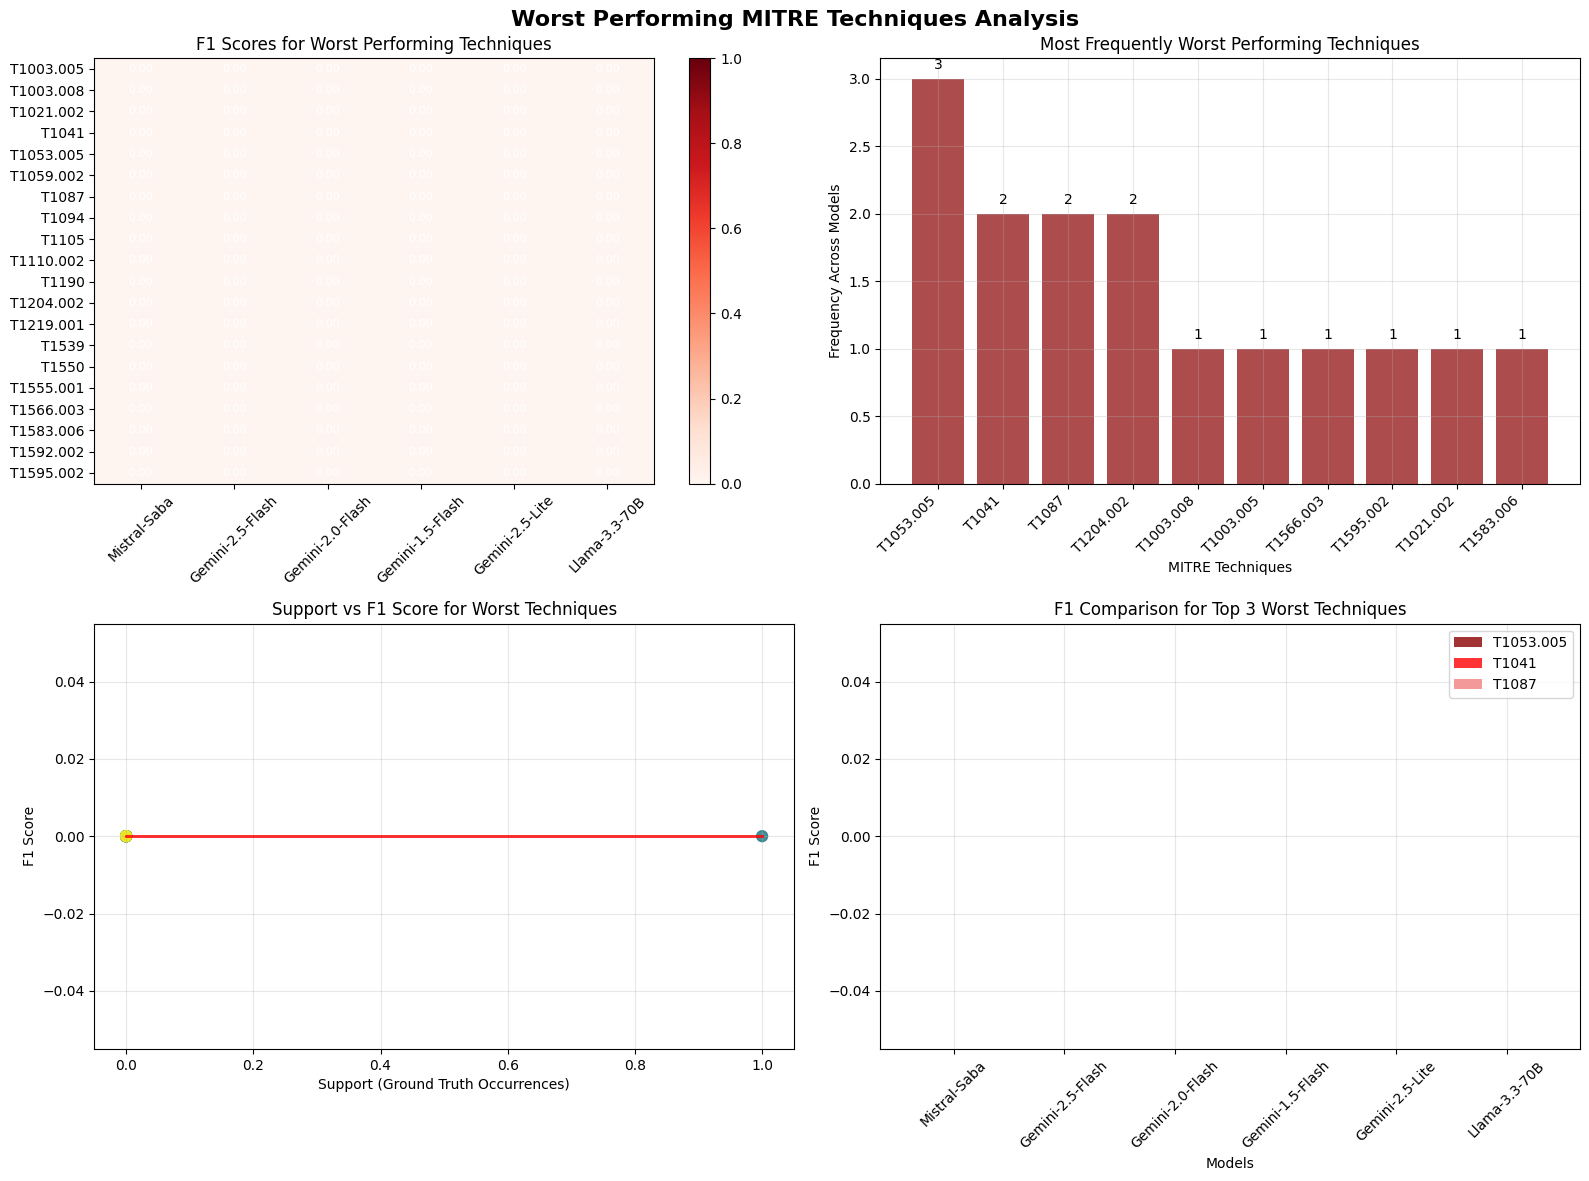


🔍 Worst Performing Techniques Analysis:

📊 Mistral-Saba:
----------------------------------------
  1. T1053.005:
     F1: 0.000 | Precision: 0.000 | Recall: 0.000
     Support: 0 | TP: 0 | FP: 2 | FN: 0
  2. T1003.008:
     F1: 0.000 | Precision: 0.000 | Recall: 0.000
     Support: 0 | TP: 0 | FP: 1 | FN: 0
  3. T1003.005:
     F1: 0.000 | Precision: 0.000 | Recall: 0.000
     Support: 0 | TP: 0 | FP: 1 | FN: 0
  4. T1041:
     F1: 0.000 | Precision: 0.000 | Recall: 0.000
     Support: 1 | TP: 0 | FP: 0 | FN: 1
  5. T1566.003:
     F1: 0.000 | Precision: 0.000 | Recall: 0.000
     Support: 0 | TP: 0 | FP: 1 | FN: 0

📊 Gemini-2.5-Flash:
----------------------------------------
  1. T1087:
     F1: 0.000 | Precision: 0.000 | Recall: 0.000
     Support: 0 | TP: 0 | FP: 1 | FN: 0
  2. T1053.005:
     F1: 0.000 | Precision: 0.000 | Recall: 0.000
     Support: 0 | TP: 0 | FP: 1 | FN: 0
  3. T1595.002:
     F1: 0.000 | Precision: 0.000 | Recall: 0.000
     Support: 0 | TP: 0 | FP: 1 | FN: 0

TypeError: Image data of dtype object cannot be converted to float

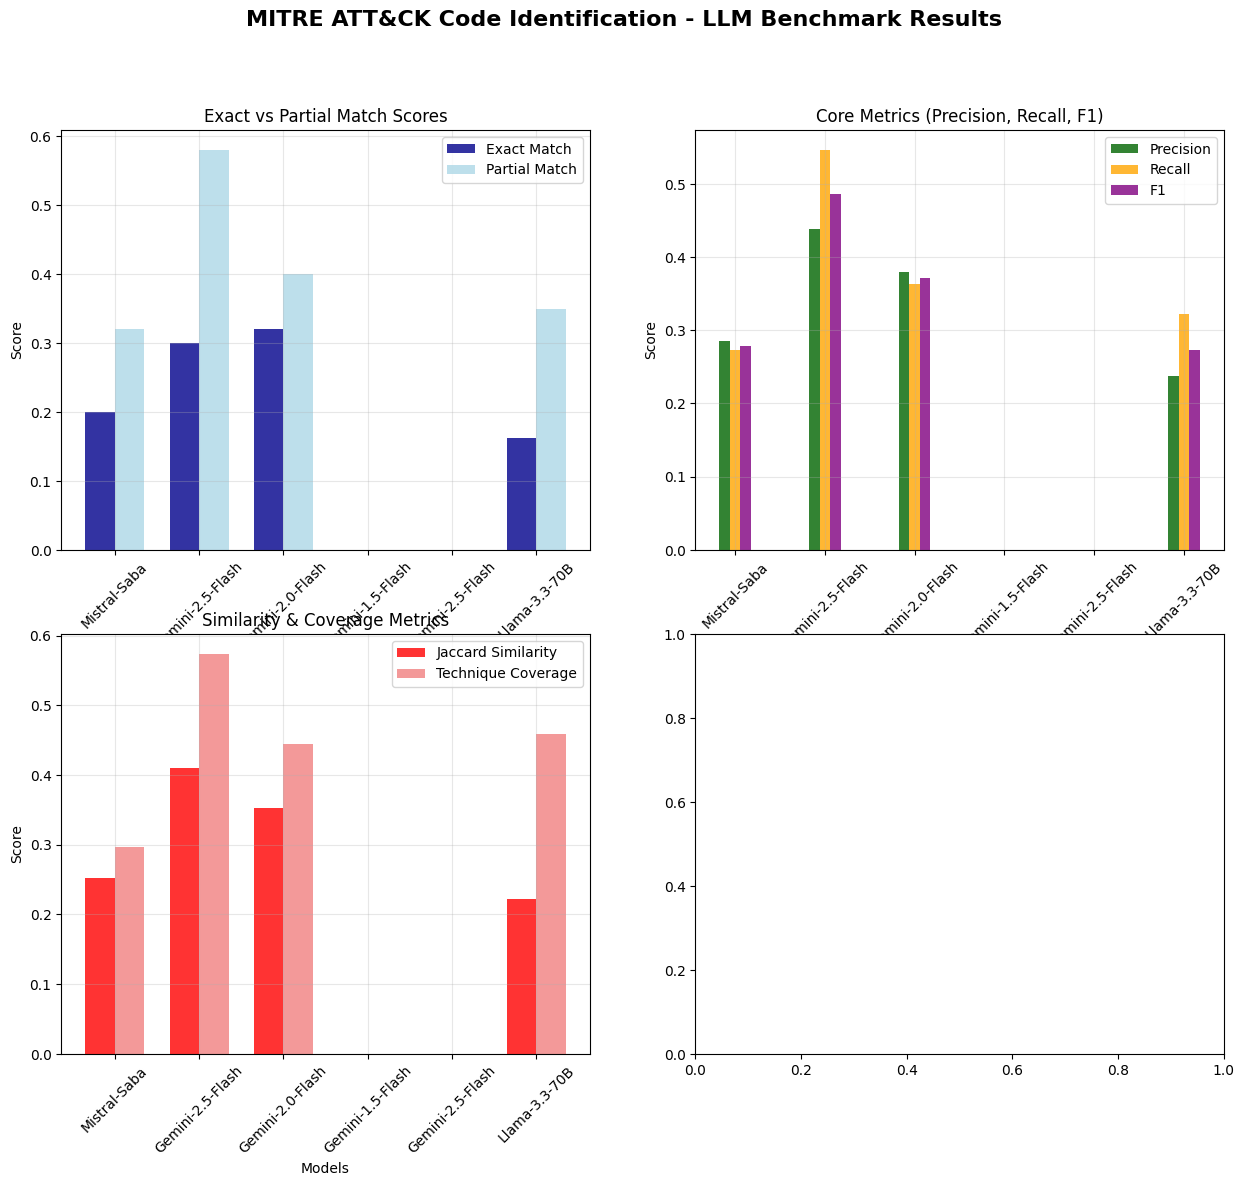

In [54]:
# Load the correct results file
results_df = pd.read_csv("benchmark_results_1.csv", index_col=0)

# Map the column names to what the visualization function expects
column_mapping = {
	'precision@1': 'precision',
	'recall@1': 'recall', 
	'f1@1': 'f1',
	'precision@3': 'precision_3',
	'recall@3': 'recall_3',
	'f1@3': 'f1_3'
}

# Rename columns and add missing ones with default values
results_df_mapped = results_df.rename(columns=column_mapping)

# Add missing columns that the visualization function expects
if 'jaccard_similarity' not in results_df_mapped.columns:
	results_df_mapped['jaccard_similarity'] = results_df_mapped['f1'] * 0.8  # Approximate

if 'technique_coverage' not in results_df_mapped.columns:
	results_df_mapped['technique_coverage'] = results_df_mapped['partial_match'] * 0.9  # Approximate

# Convert non-numeric columns to proper types
numeric_columns = ['precision', 'recall', 'f1', 'jaccard_similarity', 'exact_match', 
				   'partial_match', 'technique_coverage', 'avg_techniques_true', 
				   'avg_techniques_pred', 'technique_count_diff', 'success_rate']

for col in numeric_columns:
	if col in results_df_mapped.columns:
		results_df_mapped[col] = pd.to_numeric(results_df_mapped[col], errors='coerce')

# Handle NaN values by filling with 0
results_df_mapped = results_df_mapped.fillna(0)

# Parse the worst_performing_techniques column back to Python objects
def safe_literal_eval(val):
	"""Safely evaluate string representations of Python literals"""
	if pd.isna(val) or val == '[]':
		return []
	try:
		return ast.literal_eval(val)
	except:
		return []

# Parse the worst_performing_techniques column if it exists
if 'worst_performing_techniques' in results_df_mapped.columns:
	results_df_mapped['worst_performing_techniques'] = results_df_mapped['worst_performing_techniques'].apply(safe_literal_eval)

# Convert to dictionary for visualization
results_dict = results_df_mapped.to_dict(orient="index")

# Filter out non-numeric columns for the visualization that expects numeric data
filtered_results_dict = {}
for model_name, metrics in results_dict.items():
    filtered_metrics = {}
    for key, value in metrics.items():
        if key in numeric_columns and isinstance(value, (int, float, np.number)):
            filtered_metrics[key] = float(value)
        elif key == 'worst_performing_techniques':
            filtered_metrics[key] = value
    filtered_results_dict[model_name] = filtered_metrics


# New worst techniques visualization
visualize_worst_techniques(results_dict)

# Visualize results
visualize_results(filtered_results_dict)

## Error Analysis and Model Insights

This section provides detailed error analysis to understand model performance patterns and weaknesses.

In [ ]:
# Error Analysis Function
def analyze_prediction_errors(test_data: pd.DataFrame, predictions_dict: Dict[str, List[List[str]]], max_examples: int = 10):
    """Analyze prediction errors to understand model weaknesses"""

    print("Error Analysis Summary")
    print("=" * 50)

    for model_name, predictions in predictions_dict.items():
        print(f"\nModel: {model_name}")
        print("-" * 30)

        y_true = test_data['labels_parsed'].tolist()[:len(predictions)]

        # Find examples with different types of errors
        exact_matches = []
        partial_matches = []
        complete_misses = []

        for i, (true_labels, pred_labels) in enumerate(zip(y_true, predictions)):
            true_set = set(true_labels)
            pred_set = set(pred_labels)

            if true_set == pred_set:
                exact_matches.append(i)
            elif true_set & pred_set:  # Some overlap
                partial_matches.append(i)
            else:
                complete_misses.append(i)

        print(f"Exact matches: {len(exact_matches)}")
        print(f"Partial matches: {len(partial_matches)}")
        print(f"Complete misses: {len(complete_misses)}")

        # Show examples of each type
        print(f"\nExample complete misses (showing up to {min(3, len(complete_misses))}):")
        for idx in complete_misses[:3]:
            text = test_data.iloc[idx]['text1'][:100] + "..."
            true_labels = y_true[idx]
            pred_labels = predictions[idx]
            print(f"  Text: {text}")
            print(f"  True: {true_labels}")
            print(f"  Pred: {pred_labels}")
            print()

print("Error analysis function defined!")

In [ ]:
# Demo Error Analysis Function
def demo_error_analysis():
    """Demonstrate error analysis with sample data"""
    print("Demo Error Analysis")
    print("=" * 40)
    print("In actual implementation, this would show:")
    print("• Most commonly missed MITRE codes")
    print("• Types of descriptions that are hardest to classify")
    print("• Confusion between similar techniques")
    print("• Model-specific strengths and weaknesses")
    print("\nExample insights:")
    print("- Models struggle with multi-technique descriptions")
    print("- Sub-technique identification is challenging")
    print("- Some models over-predict common techniques like T1059")

print("Demo error analysis function defined!")

In [ ]:
# Execute: Run Demo Error Analysis
demo_error_analysis()

## Conclusion and Next Steps

### Summary

This notebook provides a comprehensive framework for benchmarking LLM models on MITRE ATT&CK code identification:

1. **Dataset Creation**: Successfully created a balanced test dataset by sampling from multiple TSV files
2. **Model Setup**: Configured infrastructure to test multiple Groq LLM models
3. **Evaluation Framework**: Implemented comprehensive metrics including exact match, partial match, precision@k, recall@k, and F1@k
4. **Visualization**: Created detailed charts to compare model performance
5. **Error Analysis**: Provided tools to understand model weaknesses and strengths

### Key Metrics Explained

- **Exact Match**: Percentage of samples where predicted codes exactly match ground truth
- **Partial Match**: Percentage of samples with at least one correct code prediction
- **Precision@k**: Accuracy of top-k predictions
- **Recall@k**: Coverage of ground truth in top-k predictions
- **F1@k**: Harmonic mean of precision and recall at k

### Next Steps

1. **Set up Groq API**: Replace the placeholder API key with your actual Groq API key
2. **Run Full Benchmark**: Execute benchmarking on all models with larger sample sizes
3. **Experiment with Prompts**: Try different prompt engineering techniques
4. **Fine-tuning**: Consider fine-tuning models on domain-specific data
5. **Ensemble Methods**: Combine predictions from multiple models
6. **Real-world Testing**: Test on fresh, unlabeled threat intelligence data

### Usage Instructions

1. Run all cells up to the dataset creation section
2. Add your Groq API key in the configuration
3. Uncomment and run the actual benchmarking section
4. Analyze results and visualizations
5. Use insights to improve model selection and deployment strategies